# Aula 12 — Laboratório: Matplotlib, Seaborn e Plotly (Prática) · Conteúdo

**Unidade 3 — Análise Exploratória de Dados e Visualização** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**🎨 Aula 12 — Laboratório: Matplotlib, Seaborn e Plotly (Prática)**

Segunda aula da Unidade 3 (Análise Exploratória de Dados e Visualização). Gráficos univariados (histograma, boxplot, violino); bivariados (dispersão, barras, mapa de calor de correlação); customização e paletas de cores — sempre com as estatísticas que sustentam a leitura (média, mediana, quartis, IQR, r, IC 95%, *n*). Exemplos com **dados sintéticos de fácil entendimento** — delivery de uma hamburgueria fictícia (600 pedidos) e usuários de um aplicativo de música fictício (nenhum dado é real). Recursos: Jupyter Notebook, Matplotlib, Seaborn e Plotly. Avaliação: **formulário avaliativo com 10 questões** — prazo de envio até 16/11/2026. O exercício prático é para treino e **não precisa ser entregue**. Materiais desta aula: livro Tópicos de Estudo (5 capítulos) · apostila completa em PDF · materiais complementares sobre correlação de Pearson e de Spearman (PDF) · pacote com notebooks e datasets · formulário avaliativo.

---
## Tópicos de Estudo — Aula 12

### Descrição

Resumo dos principais tópicos da Aula 12 — Laboratório: Matplotlib, Seaborn e Plotly, em 5 capítulos curtos.

### 1. Bibliotecas, anatomia de uma figura e escolha do gráfico

Nesta aula de laboratório vamos transformar as medidas da Aula 11 em **gráficos**. A regra que guia tudo: **cada gráfico responde a uma pergunta e traz escrito o número que sustenta a resposta** (média, mediana, quartis, r, intervalo de confiança, *n*).

#### O caso da aula (sintético)

600 pedidos de delivery de uma hamburgueria fictícia (*Brasa & Pão*) em 8 semanas: bairro, distância, veículo (moto ou bicicleta), chuva, turno, itens, valor, taxa, tempo de entrega e avaliação. No exercício, 240 usuários de um aplicativo de música fictício. Nenhum dado é real.

#### As três bibliotecas

|  |  |  |
|----|----|----|
| Biblioteca | Nível | Use quando |
| **Matplotlib** (`plt`) | baixo — controle de cada elemento | precisar customizar, anotar, montar painéis e exportar |
| **Seaborn** (`sns`) | alto — recebe DataFrame e nomes de colunas; calcula médias, IC, KDE e regressão | quiser explorar distribuições e relações rapidamente |
| **Plotly Express** (`px`) | alto — uma linha por gráfico, interativo | quiser explorar com o mouse ou compartilhar em HTML |

O Seaborn desenha **sobre** o Matplotlib: todo gráfico do Seaborn fica dentro de um `Axes`, que pode ser ajustado depois. O Plotly é independente.

#### Anatomia de uma figura

- **Figure**: a folha inteira (tamanho, título geral, `savefig`).
- **Axes**: cada área de plotagem, com eixos, título, rótulos e legenda.

Use a **interface orientada a objetos**:

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df["tempo_entrega_min"], ax=ax)
ax.set(title="Tempo de entrega", xlabel="Tempo (min)", ylabel="Pedidos")

fig, axes = plt.subplots(2, 2)   # painéis: axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

#### Qual gráfico usar?

|  |  |  |
|----|----|----|
| Pergunta | Gráfico | Número no gráfico |
| Como uma variável numérica se distribui? | histograma | média, mediana, desvio-padrão |
| Há outliers? Como grupos se comparam? | boxplot | mediana, IQR, *n* |
| Qual a forma da distribuição em cada grupo? | violino | quartis |
| Duas numéricas se relacionam? | dispersão | r de Pearson/Spearman, reta |
| Qual a média/contagem por categoria? | barras | IC 95% ou desvio-padrão, *n* |
| Como várias numéricas se relacionam? | mapa de calor | matriz de r |

### 2. Gráficos univariados: histograma, boxplot e violino

Gráficos **univariados** mostram a distribuição de uma variável: centro, dispersão, assimetria e valores atípicos.

#### Histograma

Divide a variável em classes (*bins*) e conta as observações em cada uma. Marque **média** e **mediana** com `ax.axvline`. No caso da aula: média 37,4 min, mediana 36 min, skew = 1,18 → **assimetria positiva** (alguns atrasos longos puxam a média). Poucas classes escondem detalhes; classes demais viram ruído — comece com `bins="auto"`.

In [ ]:
sns.histplot(t, bins="auto", ax=ax)
ax.axvline(t.mean(), label=f"média = {t.mean():.1f} min")
ax.axvline(t.median(), ls="--", label=f"mediana = {t.median():.0f} min")

#### Boxplot

Resumo em cinco números. A caixa vai do **Q1** ao **Q3** (altura = **IQR**), a linha interna é a **mediana**, os bigodes vão até Q1 − 1,5·IQR e Q3 + 1,5·IQR, e os pontos além disso são **outliers** (critério de Tukey). No caso: Q1 = 30, Q3 = 43, IQR = 13 → outliers acima de 62,5 min (15 pedidos).

É o melhor gráfico para **comparar grupos** (tempo por bairro: medianas de 29 min no Centro a 46 min na Serra). Limitação: esconde o tamanho da amostra — escreva o *n* nos rótulos ou sobreponha os pontos com `sns.stripplot`. Use `showmeans=True` para marcar também a média.

#### Violino

Combina o boxplot com a **densidade estimada (KDE)**: a largura mostra onde os valores se concentram. Parâmetros úteis: `inner="quart"` (Q1, mediana, Q3), `split=True` (dois grupos em metades do mesmo violino) e `cut=0` (não ultrapassa os valores observados). No caso, com chuva a distribuição inteira sobe (almoço: mediana de 31 para 39 min).

In [ ]:
sns.violinplot(data=df, x="turno", y="tempo_entrega_min", hue="chuva",
               split=True, inner="quart", cut=0, ax=ax)

### 3. Gráficos bivariados: dispersão, barras e mapa de calor

Gráficos **bivariados** cruzam duas variáveis. A estatística muda conforme os tipos envolvidos.

#### Dispersão (scatter) — numérica × numérica

Acompanhe de **r de Pearson** (relação linear), **ρ de Spearman** (monotônica, robusta a outliers) e da **reta de regressão** (`sns.regplot`; a faixa é o IC 95% da reta). `hue` e `style` acrescentam variáveis. No caso: distância × tempo, r = 0,71, tempo ≈ 25,8 + 2,80 × km (cada km a mais ≈ 2,8 min).

**Atenção à variável de confusão:** a bicicleta parece mais rápida (mediana 33 × 36 min), mas só faz entregas de até 3 km. Na mesma faixa de distância ela é mais lenta (33 × 29 min).

#### Barras — categórica (× numérica)

`sns.barplot` calcula uma estatística por categoria (média, por padrão) e desenha uma barra de erro; `sns.countplot` apenas conta. Sempre diga qual barra de erro foi usada:

|                       |                                 |
|-----------------------|---------------------------------|
| Parâmetro             | Significado                     |
| `errorbar=("ci", 95)` | IC 95% da média (padrão)        |
| `errorbar="sd"`       | média ± 1 desvio-padrão         |
| `errorbar="se"`       | média ± 1 erro-padrão           |
| `estimator="median"`  | usa a mediana no lugar da média |

Barras começam no zero. No caso, o ticket médio vai de R\$ 89 (segunda) a R\$ 118 (sábado).

#### Mapa de calor da correlação — várias numéricas

Paleta **divergente** centrada no zero, valores escritos e máscara do triângulo superior:

In [ ]:
corr = df[colunas].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, center=0, ax=ax)

No caso: distância × taxa = 0,99 (redundantes), distância × tempo = 0,71, tempo × avaliação = −0,59, itens × valor = 0,92. Mapas de calor também servem para tabelas dinâmicas (bairro × turno), com paleta sequencial.

### 4. Customização e paletas de cores

#### Paletas: escolha pelo tipo de dado

|  |  |  |
|----|----|----|
| Tipo | Quando usar | Exemplos |
| Qualitativa | categorias sem ordem (bairro, plano) | `"colorblind"`, `"Set2"`, `"tab10"` |
| Sequencial | valores que só crescem (contagem, tempo) | `"viridis"`, `"Greens"`, `"rocket"` |
| Divergente | valores com ponto central (correlação, variação) | `"vlag"`, `"RdBu"`, `"coolwarm"` |

Evite o arco-íris (`jet`): cria fronteiras falsas e falha para daltônicos e em impressão. Prefira `sns.set_theme(palette="colorblind")` e não dependa só da cor — use também forma do marcador (`style=`), rótulos e legenda.

#### Customizar é comunicar

- **Ordene** as categorias pelo valor.
- Use **cinza** para o contexto e **uma cor** para o destaque.
- **Rotule diretamente**: `ax.bar_label(ax.containers[0])`.
- Escreva no **título a conclusão** ("Serra: entregas levam 46 min — 17 a mais que no Centro").
- Eixos com **unidade**; fonte dos dados no rodapé (`fig.text`).
- Remova o que não ajuda: `sns.despine()`, grades desnecessárias.

#### Comandos de customização

In [ ]:
sns.set_theme(style="whitegrid", palette="colorblind")
ax.set(title="...", xlabel="... (min)", ylabel="...", ylim=(0, 140))
ax.axhline(y, ls="--"); ax.axvspan(a, b, alpha=0.1)
ax.annotate("texto", xy=(x0, y0), xytext=(x1, y1), arrowprops=dict(arrowstyle="->"))
fig.suptitle("Título do painel"); fig.tight_layout()
fig.savefig("figura.png", dpi=200, bbox_inches="tight")

#### Checklist de um bom gráfico

1.  Título com a conclusão.
2.  Eixos com nome e unidade.
3.  Estatística identificada (média? mediana? IC 95%? desvio-padrão?).
4.  *n* por grupo quando há comparação.
5.  Paleta adequada e acessível; cor com significado.
6.  Barras a partir do zero; sem 3D, pizza com muitas fatias ou dois eixos y.
7.  Fonte dos dados.

### 5. Plotly, roteiro do laboratório e materiais

#### Plotly Express: gráficos interativos

O Plotly faz em uma linha os mesmos gráficos com **interatividade**: *hover* com os valores, zoom, filtro clicando na legenda e exportação para HTML que abre em qualquer navegador. No boxplot do Plotly, o *hover* já mostra mínimo, Q1, mediana, Q3, máximo e as cercas.

|  |  |  |
|----|----|----|
| Gráfico | Função | Parâmetros úteis |
| Histograma | `px.histogram` | `nbins`, `marginal="box"` |
| Boxplot / violino | `px.box` / `px.violin` | `points="all"`, `box=True` |
| Dispersão | `px.scatter` | `color`, `symbol`, `hover_data` |
| Mapa de calor | `px.imshow` | `text_auto=True`, `zmin=-1`, `zmax=1` |

In [ ]:
fig = px.scatter(df, x="distancia_km", y="tempo_entrega_min", color="chuva",
                 hover_data=["bairro", "valor_pedido", "avaliacao"])
fig.write_html("graficos/dispersao.html", include_plotlyjs="cdn")
fig.show()

#### Roteiro do laboratório (1h30)

|           |                                                   |
|-----------|---------------------------------------------------|
| Tempo     | Parte                                             |
| 0–10 min  | Preparação, tema, paleta e anatomia de uma figura |
| 10–35 min | Univariados: histograma, boxplot, violino         |
| 35–60 min | Bivariados: dispersão, barras, mapa de calor      |
| 60–75 min | Customização, paletas e painel 2×2                |
| 75–90 min | Plotly e fechamento                               |

#### Materiais e avaliação

- **Apostila (PDF)**: conteúdo completo, com as figuras do laboratório e a colinha de comandos.
- **Pacote**: notebook guiado (com saídas), exercício prático com resultados esperados, gabarito, dados e `gerar_dados.py`.
- **Exercício prático** (app de música, 9 passos): treino, **não precisa ser entregue**.
- **Formulário avaliativo**: 10 questões objetivas — prazo **16/11/2026, 23:59**.

---
## Conteúdo — Aula 12 (PDF)

> Apostila completa da Aula 12 — Laboratório: Matplotlib, Seaborn e Plotly: as três bibliotecas e a anatomia de uma figura, histograma, boxplot e violino, dispersão com r e reta de regressão, barras com IC 95%, mapa de calor da correlação, paletas de cores, customização e Plotly, com o roteiro do laboratório de 1h30, o exercício prático e uma colinha de comandos.

> Convertido de [`Aula12_Laboratorio_Visualizacao.pdf`](Aula12_Laboratorio_Visualizacao.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS · DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 12 - Laboratório: Matplotlib, Seaborn e Plotly

Gráficos univariados (histograma, boxplot, violino); bivariados (dispersão, barras, mapa de calor de correlação); customização e paletas de cores

| Unidade | Unidade 3 - Análise Exploratória de Dados e Visualização (Aula 12, segunda aula da unidade) |
|----------------|------------------------------------------------------------------------------------------------------------------------------|
| Natureza | Aula prática (laboratório) em Jupyter Notebook |
| Duração | 1h30 - laboratório guiado (≈ 75 min) + fechamento e início do exercício (≈ 15 min) |
| Pré-requisitos | Aulas 04-05 (Pandas) e Aula 11 (estatística descritiva e correlação) |
| Recursos | Jupyter Notebook, matplotlib , seaborn , plotly , pandas , scipy ; dados sintéticos |
| Avaliação | Formulário avaliativo (10 questões) - prazo 16/11/2026, 23:59. O exercício prático é para treino e não precisa ser entregue. |
| Professor | Plácido Antônio de Souza Neto |

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

- Escolher o gráfico adequado à pergunta e ao tipo das variáveis (univariado ou bivariado; numérica ou categórica). 1.
- Construir histogramas, boxplots e violinos e anotar neles média, mediana, quartis, IQR e outliers. 2.
- Construir gráficos de dispersão, de barras e mapas de calor e anotar r de Pearson/ Spearman, reta de regressão, intervalo de confiança e tamanho de amostra ( n ). 3.
- Customizar figuras com a interface orientada a objetos do Matplotlib: títulos, rótulos, anotações, destaque, painéis e exportação. 4.
- Selecionar paletas qualitativas, sequenciais e divergentes adequadas aos dados e seguras para daltônicos. 5.
- Criar gráficos interativos com Plotly Express e exportá-los para HTML. 6.

### Sumário

### Parte I - Fundamentos

- 1.1 Por que visualizar · 1.2 As três bibliotecas · 1.3 Anatomia de uma figura · 1.4 Qual gráfico usar
- 1.5 Histograma · 1.6 Boxplot · 1.7 Violino · 1.8 Dispersão · 1.9 Barras · 1.10 Mapa de calor
- 1.11 Paletas de cores · 1.12 Customização · 1.13 Plotly: gráficos interativos

### Parte II - Laboratório guiado: delivery da hamburgueria

Parte III - Exercício prático: app de música (sem entrega)

Parte IV - Formulário avaliativo

Apêndice A - Colinha de visualização · Apêndice B - Referências

### SOBRE OS DADOS USADOS NESTA AULA

Os dois conjuntos são sintéticos e foram escolhidos por serem de fácil entendimento: 600 pedidos de delivery de uma hamburgueria fictícia ( Brasa &amp; Pão ), com bairro, distância, veículo, chuva, turno, valor, tempo de entrega e avaliação; e 240 usuários de um aplicativo de música fictício (idade, plano, gênero favorito, horas ouvidas, anúncios e satisfação). Foram gerados por gerar\_dados.py (semente fixa) para que cada gráfico tenha algo a mostrar: uma distribuição assimétrica, outliers, uma relação linear forte, uma variável redundante e uma variável de confusão. Nenhum registro corresponde a pessoa ou empresa real.

### Parte I - Fundamentos

Cada gráfico responde a uma pergunta - e deve trazer o número que sustenta a resposta

### 1.1 Por que visualizar?

Na Aula 11 resumimos os dados com números. Mas números iguais podem esconder dados muito diferentes: o quarteto de Anscombe (1973) são quatro conjuntos com a mesma média, a mesma variância e o mesmo r ≈ 0,82 - e, no gráfico, um é linear, outro é uma curva, outro tem um único outlier que cria a correlação. Por isso, na AED resumo numérico e gráfico andam juntos : o gráfico mostra a forma; o número dá a medida precisa. Nesta aula, todo gráfico traz escrito o valor que justifica a sua leitura.

### 1.2 As três bibliotecas

| Biblioteca | Nível | Ponto forte | Use quando |
|-----------------------|-----------------------------------------------|------------------------------------------------------------------------------------|------------------------------------------------------------------|
| Matplotlib ( plt ) | baixo - controle total de cada elemento | customização fina, anotações, painéis, exportação para relatório | precisar ajustar detalhes ou montar a figura final |
| Seaborn ( sns ) | alto - recebe um DataFrame e nomes de colunas | gráficos estatísticos prontos: calcula médias, IC, KDE, regressão; temas e paletas | explorar rapidamente relações e distribuições |
| Plotly Express ( px ) | alto - uma linha por gráfico | interatividade ( hover , zoom, filtro pela legenda), exportação para HTML | explorar interativamente ou compartilhar com quem não usa Python |

Seaborn é construído sobre o Matplotlib: todo gráfico do Seaborn é desenhado em um Axes do Matplotlib, que pode ser customizado depois. O Plotly é independente e gera gráficos para o navegador.

### 1.3 Anatomia de uma figura no Matplotlib

A Figure é a folha inteira (tamanho, título geral, exportação); cada Axes é uma área de plotagem com seus eixos, título, rótulos e legenda. Use sempre a interface orientada a objetos , que deixa explícito em qual gráfico cada comando atua:

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))            # 1 Figure + 1 Axes
sns.histplot(df["tempo_entrega_min"], ax=ax)      # Seaborn desenha DENTRO do Axes
ax.axvline(df["tempo_entrega_min"].median(), ls="--", label="mediana")
ax.set(title="Tempo de entrega", xlabel="Tempo (min)", ylabel="Pedidos")
ax.legend()
fig.savefig("figuras/histograma.png", dpi=200, bbox_inches="tight")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))   # grade 2×2: axes[0, 0], axes[0, 1]...

### 1.4 Qual gráfico usar - e que número colocar nele

| Pergunta | Variáveis | Gráfico | Estatística no gráfico |
|---------------------------------------------|-------------------------|---------------|--------------------------------------------------|
| Como os valores se distribuem? | 1 numérica | histograma | média, mediana, desvio-padrão, assimetria |
| Há outliers? Como grupos se comparam? | numérica × categórica | boxplot | mediana, Q1, Q3, IQR, n por grupo |
| Qual a forma da distribuição em cada grupo? | numérica × categórica | violino | quartis ( inner="quart" ), mediana |
| Duas numéricas se relacionam? | numérica × numérica | dispersão | r de Pearson e/ou Spearman, reta de regressão |
| Qual a média ou a contagem por categoria? | categórica (× numérica) | barras | média ± IC 95% (ou desvio-padrão - diga qual), n |
| Como várias numéricas se relacionam? | várias numéricas | mapa de calor | matriz de r, escala de -1 a 1 |

### 1.5 Histograma

Divide a variável em classes ( bins ) e mostra quantas observações caem em cada uma. Revela o centro , a dispersão , a assimetria e se há mais de um pico. Marque média e mediana com linhas verticais: se a média fica à direita da mediana, há cauda à direita (assimetria positiva). O número de classes muda a leitura - comece com bins="auto" e ajuste.

Figura 1 - Tempo de entrega: média 37,4 min, mediana 36 min, skew = 1,18. A faixa sombreada é média ± 1 desvio-padrão.

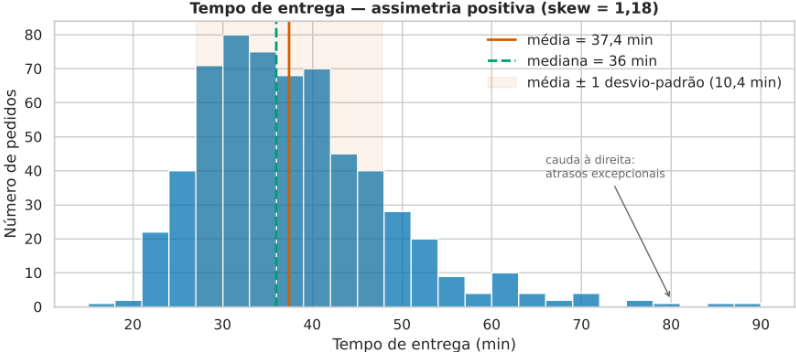

In [ ]:
sns.histplot(t, bins=range(15, 92, 3), ax=ax)
ax.axvline(t.mean(), color="C3", label=f"média = {t.mean():.1f} min")
ax.axvline(t.median(), color="C2", ls="--", label=f"mediana = {t.median():.0f} min")
ax.axvspan(t.mean() - t.std(), t.mean() + t.std(), alpha=0.07)

### 1.6 Boxplot

Resume a distribuição em cinco números: a caixa vai do Q1 (25%) ao Q3 (75%) - sua altura é o IQR ; a linha interna é a mediana ; os bigodes vão até o último valor dentro de Q1 - 1,5·IQR e Q3 + 1,5·IQR; os pontos além disso são outliers (critério de Tukey). É o melhor gráfico para comparar grupos . Limitação: esconde o tamanho da amostra e a forma (dois picos, por exemplo) - escreva o n no rótulo e, se necessário, sobreponha os pontos com stripplot .

Figura 2 - Tempo por bairro. Para todos os pedidos: Q1 = 30, mediana = 36, Q3 = 43, IQR = 13 min; outliers acima de 62,5 min.

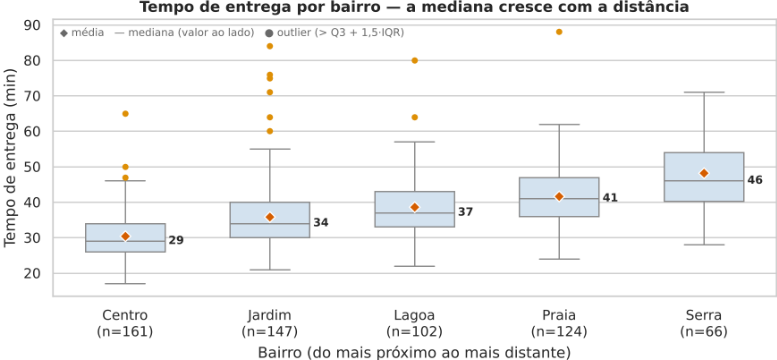

### 1.7 Violino

Combina o boxplot com uma estimativa de densidade (KDE) : a largura do violino indica onde os valores se concentram. inner="quart" desenha Q1, mediana e Q3; split=True põe dois grupos (ex.: com e sem chuva) em metades do mesmo violino; cut=0 impede que a curva ultrapasse os valores observados.

Figura 3 - Com chuva, a distribuição inteira sobe: no almoço a mediana passa de 31 para 39 min; no jantar, de 36 para 40 min.

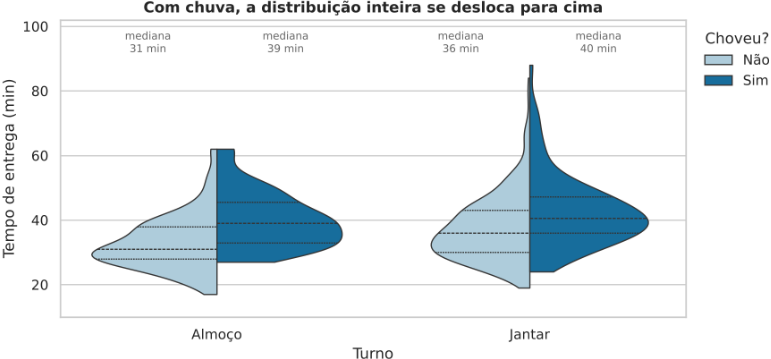

### 1.8 Dispersão (scatter)

Cada ponto é uma observação com duas medidas numéricas. Acompanhe o gráfico de: r de Pearson (força da relação linear ), ρ de Spearman (relação monotônica, robusta a outliers) e a reta de regressão ( sns.regplot ; a faixa sombreada é o IC 95% da reta). Cor ( hue ) e forma ( style ) acrescentam uma terceira e uma quarta variável.

Figura 4 - Distância × tempo: r = 0,71, ρ = 0,72, tempo ≈ 25,8 + 2,80 × km (R² = 0,51).

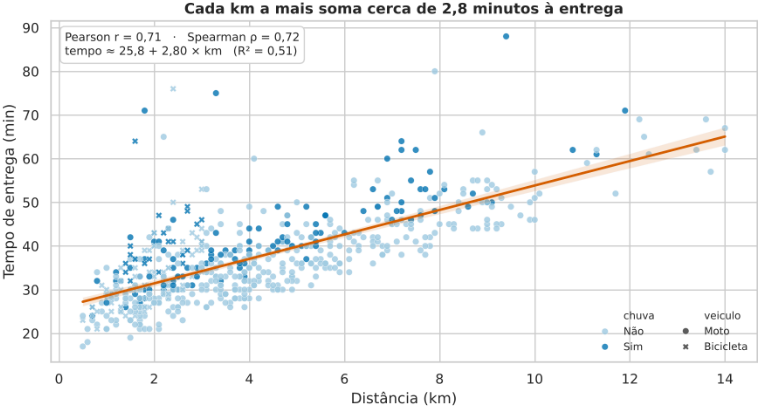

### VARIÁVEL DE CONFUSÃO NO GRÁFICO

No boxplot, a bicicleta parece mais rápida (mediana 33 × 36 min da moto). Mas a bicicleta só faz entregas de até 3 km. Comparando apenas entregas de até 3 km, a bicicleta é mais lenta (mediana 33 × 29 min). A distância confunde a comparação - e a dispersão colorida por veículo, restrita às entregas curtas, mostra isso.

### 1.9 Gráfico de barras

No Seaborn, barplot calcula uma estatística por categoria (média, por padrão) e desenha uma barra de erro; countplot apenas conta linhas. Sempre informe qual barra de erro foi usada e, ao comparar grupos, o n de cada um. Barras devem começar no zero.

| Parâmetro | O que a barra de erro mostra |
|------------------------------|------------------------------------------------------------------------------|
| errorbar=("ci", 95) (padrão) | intervalo de confiança de 95% da média (bootstrap) - incerteza sobre a média |
| errorbar="sd" | média ± 1 desvio-padrão - dispersão dos dados |
| errorbar="se" | média ± 1 erro-padrão |
| estimator="median" | troca a média pela mediana |

Figura 5 - (a) Ticket médio por dia com IC 95% e n; sexta a domingo em destaque. (b) Contagem de pedidos por bairro, ordenada, com rótulos diretos.

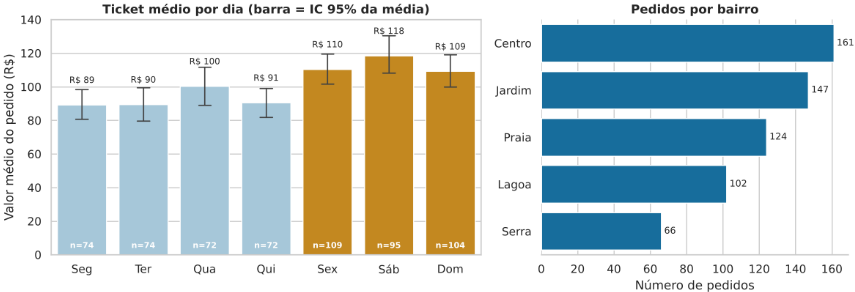

### 1.10 Mapa de calor da correlação

Mostra, de uma vez, a matriz de r entre todas as variáveis numéricas. Boas práticas: paleta divergente centrada no zero ( cmap="vlag", center=0, vmin=-1, vmax=1 ), valores escritos em cada célula ( annot=True, fmt=".2f" ) e máscara do triângulo superior, pois a matriz é simétrica. Mapas de calor também servem para tabelas dinâmicas (ex.: mediana do tempo por bairro × turno) - nesse caso, com paleta sequencial.

Figura 6 - Distância × taxa = 0,99 (redundantes); distância × tempo = 0,71; tempo × avaliação = -0,59; itens × valor = 0,92.

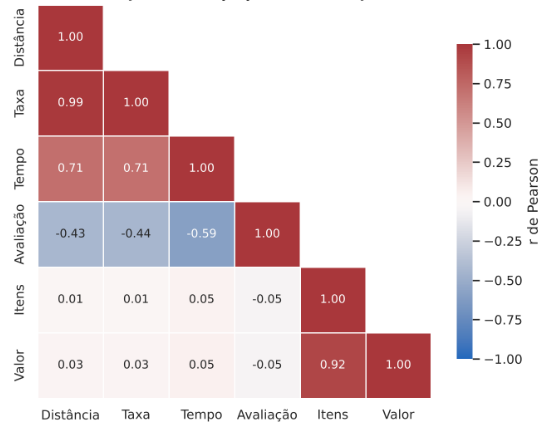

In [ ]:
corr = df[colunas_numericas].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag",
            vmin=-1, vmax=1, center=0, square=True, linewidths=1, ax=ax)

### 1.11 Paletas de cores

A paleta deve seguir o tipo de dado , e a cor deve ter significado (identificar um grupo, codificar uma intensidade ou destacar a mensagem) - nunca ser só decoração.

| Tipo | Quando usar | Exemplos |
|-------------|--------------------------------------------|----------------------------------------------------------------|
| Qualitativa | "colorblind" , | categorias sem ordem (bairro, plano, veículo) "Set2" , "tab10" |
| | densidade) "viridis" , "Greens" , "rocket" | Sequencial valores que só crescem (contagem, tempo, |
| Divergente | "vlag" , "RdBu" , "coolwarm" | valores com ponto central significativo (correlação, |

Figura 7 - Paletas por tipo de dado. O arco-íris (jet) cria fronteiras falsas e falha para daltônicos e em impressão em tons de cinza.

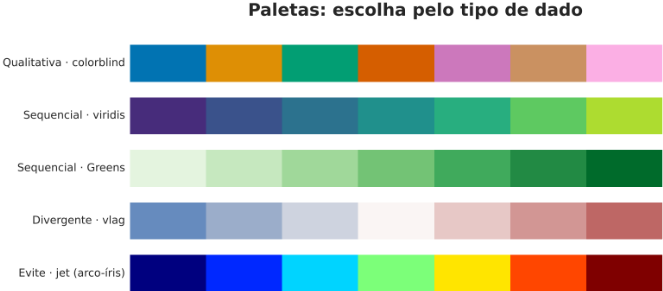

### ACESSIBILIDADE

Cerca de 8% dos homens têm alguma deficiência na percepção de cores. Prefira sns.set\_theme(palette="colorblind") ou viridis , e nunca dependa só da cor: use também forma do marcador ( style= ), rótulos diretos e legendas.

### 1.12 Customização: do gráfico padrão ao gráfico que comunica

Customizar é tirar o que não ajuda e destacar o que importa : ordenar as categorias pelo valor, rotular as barras diretamente ( ax.bar\_label ), usar cinza para o contexto e uma única cor para o destaque, escrever no título a conclusão e indicar a fonte.

Figura 8 - Antes: ordem alfabética, cores sem significado, título = nome da coluna. Depois: ordenado, destaque, rótulos diretos e título com a mensagem.

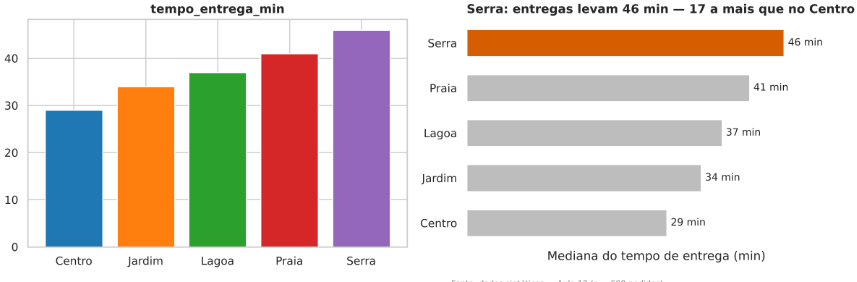

| Elemento | Comando |
|--------------------------|-------------------------------------------------------------------------------------------------|
| Tema e paleta globais | sns.set_theme(style="whitegrid", palette="colorblind") |
| Título, rótulos, limites | ax.set(title=..., xlabel=..., ylabel=..., ylim=(0, 140)) |
| Linha de referência | ax.axvline(x) , ax.axhline(y) , faixa: ax.axvspan(a, b) |
| Texto e seta | ax.text(x, y, "...") , ax.annotate("...", xy=..., xytext=..., arrowprops=dict(arrowstyle="->")) |
| Rótulos nas barras | ax.bar_label(ax.containers[0], padding=3) |
| Remover bordas | sns.despine(ax=ax, left=True) |
| Painel e título geral | fig, axes = plt.subplots(2, 2) , fig.suptitle(...) , fig.tight_layout() |
| Exportar | fig.savefig("fig.png", dpi=200, bbox_inches="tight") |

### 1.13 Plotly: gráficos interativos

O Plotly Express gera em uma linha os mesmos gráficos, agora interativos : passar o mouse mostra os valores ( hover ), é possível dar zoom, esconder grupos clicando na legenda e exportar para um arquivo HTML que abre em qualquer navegador. No boxplot do Plotly, o hover já mostra mínimo, Q1, mediana, Q3, máximo e as cercas.

| Gráfico | Plotly Express | Parâmetros úteis |
|-------------------|--------------------|--------------------------------------------------------------------|
| Histograma | px.histogram | nbins , marginal="box" ou "violin" |
| Boxplot / violino | px.box / px.violin | points="all" ou "outliers" ; box=True no violino |
| Dispersão | px.scatter | color , symbol , hover_data=[...] |
| Barras | px.bar | text_auto=True , error_y |
| Mapa de calor | px.imshow | text_auto=True , zmin=-1, zmax=1 , color_continuous_scale="RdBu_r" |

In [ ]:
fig = px.scatter(df, x="distancia_km", y="tempo_entrega_min", color="chuva",
                 hover_data=["bairro", "valor_pedido", "avaliacao"],
                 title="Distância × tempo (r = 0,71)")
fig.add_vline(x=4.1, line_dash="dash")                     # linhas de referência
fig.write_html("graficos/dispersao.html", include_plotlyjs="cdn")
fig.show()

### Parte II - Laboratório guiado: delivery da hamburgueria

Notebook Aula12\_Visualizacao\_Laboratorio.ipynb · 1h30

O notebook guiado segue o roteiro abaixo. Execute célula por célula, leia o resultado e responda à pergunta de cada parte antes de seguir. As figuras desta apostila foram geradas por ele (pasta figuras/ ), e os gráficos interativos ficam em graficos/ .

| Tempo | Parte do notebook | O que fazer | Resultado de referência |
|-----------|--------------------------|--------------------------------------------------------------------------------------------------|---------------------------------------------------------------|
| 0-10 min | 0. Preparação e anatomia | importar bibliotecas, definir tema e paleta, carregar o CSV; gráfico de linha de pedidos por dia | 600 × 13; média de 10,7 pedidos/dia, picos de sexta a domingo |
| 10-20 min | 1.1 Histograma | calcular resumo; marcar média, mediana e média ± dp; comparar bins | média 37,4; mediana 36; dp 10,4; skew 1,18 |
| 20-28 min | 1.2 Boxplot | calcular Q1, Q3, IQR e limites de Tukey; boxplot por bairro com n e medianas | IQR 13 min; 15 outliers (> 62,5 min); medianas 29 → 46 min |
| 28-35 min | 1.3 Violino | violino dividido por chuva; comparar box × violino × pontos | chuva: +8 min no almoço, +4 no jantar (medianas) |
| 35-47 min | 2.1 Dispersão | r, ρ e reta; investigar bicicleta × moto | r = 0,71; 2,8 min/km; bicicleta mais lenta até 3 km |
| 47-53 min | 2.2 Barras | ticket médio por dia com IC 95% e n ; contagem por bairro | R$ 89 (seg) a R$ 118 (sáb) |
| 53-60 min | 2.3 Mapa de calor | matriz de correlação com máscara; tabela dinâmica bairro × turno | maiores &#124;r&#124;: 0,99; 0,92; 0,71; -0,59 |
| 60-75 min | 3. Customização | paletas; antes × depois; painel 2×2 exportado | 09_painel_gerencia.png |
| 75-85 min | 4. Plotly | histograma com box marginal, dispersão com hover , box/violino, mapa de calor; exportar HTML | 3 arquivos em graficos/ |
| 85-90 min | Fechamento | revisar o quadro "qual gráfico usar" e o checklist; apresentar o exercício | - |

Figura 9 - Painel 2×2 para a gerência, produto final da Parte 3 do laboratório.

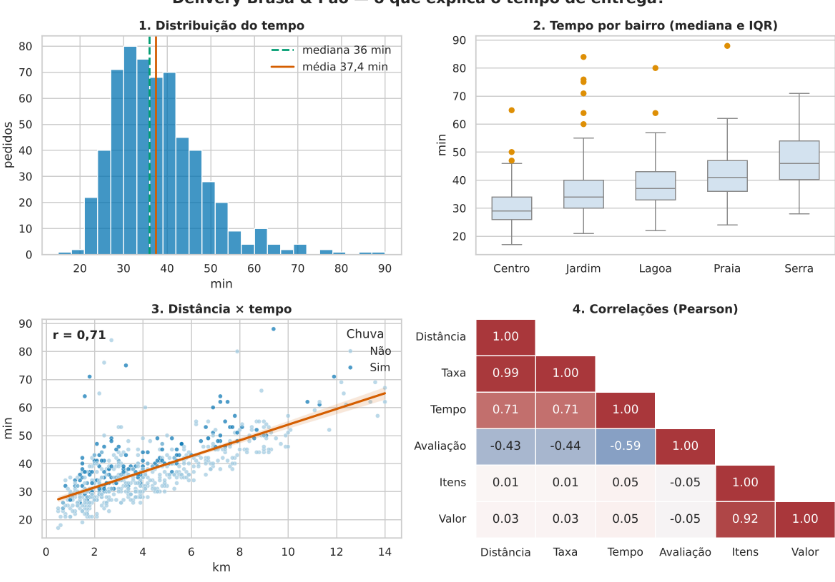

### Parte III - Exercício prático: app de música (sem entrega)

Notebook Aula12\_Exercicio\_Pratico.ipynb · gabarito em Aula12\_Exercicio\_Gabarito.ipynb

Aplique o mesmo roteiro aos 240 usuários de um aplicativo de música fictício. Cada passo traz o resultado esperado para conferência. O exercício é para treino e não precisa ser entregue .

| Passo | Tarefa | Resultado esperado |
|---------|------------------------------------------------------|--------------------------------------------------------------------|
| 1 | Carregar e conhecer os dados | 240 × 9; 151 Gratuito e 89 Premium |
| 2 | Histograma de horas_semana com média e mediana | média 16,5 h; mediana 16,2 h; skew 0,29 (quase simétrica) |
| 3 | Boxplot de horas por plano, com n e medianas | Gratuito 15,3 h; Premium 18,5 h; 1 outlier no conjunto |
| 4 | Violino da satisfação por plano | medianas 3,6 (Gratuito) e 7,3 (Premium) |
| 5 | Dispersão idade × horas com r e reta | r = -0,65; horas ≈ 25,0 - 0,21 × idade |
| 6 | Barras de horas médias por gênero (IC 95%, n ) | Eletrônica 19,6 h (maior); Rock 15,0 h (menor) |
| 7 | Mapa de calor da correlação + desafio | anúncios × satisfação = -0,82; só Gratuito: -0,42 (plano confunde) |
| 8 | Painel 2×2 customizado e exportado | figuras/exercicio_painel.png |
| 9 | Plotly: dispersão com hover e boxplot; exportar HTML | graficos/exercicio_dispersao.html |


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha de visualização

In [ ]:
import matplotlib.pyplot as plt, seaborn as sns, plotly.express as px
sns.set_theme(style="whitegrid", palette="colorblind")

# ---------- UNIVARIADOS ----------
sns.histplot(df, x="var", bins="auto", kde=False, ax=ax)          # histograma
ax.axvline(df["var"].mean()); ax.axvline(df["var"].median(), ls="--")
sns.boxplot(df, x="grupo", y="var", showmeans=True, ax=ax)          # boxplot
sns.violinplot(df, x="grupo", y="var", hue="h", split=True,
               inner="quart", cut=0, ax=ax)                        # violino
sns.stripplot(df, x="grupo", y="var", alpha=.4, jitter=.25, ax=ax)  # pontos

# ---------- BIVARIADOS ----------
sns.scatterplot(df, x="x", y="y", hue="cat", style="cat2", ax=ax)   # dispersão
sns.regplot(df, x="x", y="y", scatter=False, ax=ax)                # reta + IC 95%
r = stats.pearsonr(df.x, df.y)[0]; rho = stats.spearmanr(df.x, df.y)[0]
sns.barplot(df, x="cat", y="var", errorbar=("ci", 95), capsize=.2, ax=ax)
sns.countplot(df, y="cat", order=df["cat"].value_counts().index, ax=ax)
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)          # correlação

# ---------- CUSTOMIZAÇÃO ----------
ax.set(title="Conclusão em uma frase", xlabel="x (unidade)", ylabel="y (unidade)")
ax.bar_label(ax.containers[0], fmt="%.0f"); sns.despine(ax=ax)
ax.annotate("texto", xy=(x0, y0), xytext=(x1, y1), arrowprops=dict(arrowstyle="->"))
fig.suptitle("Título do painel"); fig.tight_layout()
fig.savefig("figura.png", dpi=200, bbox_inches="tight")

# ---------- PLOTLY ----------
px.histogram(df, x="var", marginal="box"); px.box(df, x="g", y="var", points="all")
px.scatter(df, x="x", y="y", color="cat", hover_data=["col1", "col2"])
px.imshow(corr, text_auto=".2f", zmin=-1, zmax=1, color_continuous_scale="RdBu_r")
fig.write_html("grafico.html", include_plotlyjs="cdn")

### Checklist de um bom gráfico

- O título diz a conclusão , não só o nome da variável. 1.
- Eixos com nome e unidade (min, km, R$, h). 2.
- A estatística mostrada está identificada : média? mediana? IC 95%? desvio-padrão? 3.
- Ao comparar grupos, o n de cada grupo aparece. 4.
- Paleta adequada ao tipo de dado, segura para daltônicos, e cor com significado. 5.
- Barras começam no zero; evite 3D, pizza com muitas fatias e dois eixos y. 6.
- Fonte dos dados no rodapé. 7.

### Apêndice B - Referências

- HUNTER, J. D. Matplotlib: a 2D graphics environment. Computing in Science &amp; Engineering , v. 9, n. 3, p. 90-95, 2007. Documentação: matplotlib.org. ·
- WASKOM, M. L. seaborn: statistical data visualization. Journal of Open Source Software , v. 6, n. 60, 3021, 2021. Documentação: seaborn.pydata.org. ·
- PLOTLY TECHNOLOGIES. Plotly Python Open Source Graphing Library . Documentação: plotly.com/python. ·

- VANDERPLAS, J. Python Data Science Handbook . 2. ed. O'Reilly, 2023 - capítulos de visualização com Matplotlib. ·
- WILKE, C. O. Fundamentals of Data Visualization . O'Reilly, 2019 (disponível em clauswilke.com/dataviz). ·
- KNAFLIC, C. N. Storytelling com Dados . Alta Books, 2019. ·
- ANSCOMBE, F. J. Graphs in statistical analysis. The American Statistician , v. 27, n. 1, p. 17-21, 1973. ·
- TUKEY, J. W. Exploratory Data Analysis . Addison-Wesley, 1977. ·

---
## Material complementar — Correlação de Pearson (PDF)

> Material complementar da Aula 12, progressivo, sobre o coeficiente de correlação de Pearson: associação entre variáveis, covariância e padronização, cálculo à mão passo a passo, leitura do r e do r², armadilhas (relações não lineares, outliers, restrição de amplitude, variável de confusão, variância zero), p-valor e intervalo de confiança, e aplicações nos datasets da aula até a correlação parcial. Inclui 8 exercícios com respostas. Leia antes do material de Spearman.

> Convertido de [`Aula12_Complementar_Correlacao_Pearson.pdf`](Aula12_Complementar_Correlacao_Pearson.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

| Relação com a aula | Aprofunda o r de Pearson usado nos gráficos de dispersão e no mapa de calor da Aula 12 - Laboratório: Matplotlib, Seaborn e Plotly |
|----------------------|--------------------------------------------------------------------------------------------------------------------------------------|
| Como está organizado | Progressivo: intuição → cálculo à mão → interpretação → armadilhas → aplicações nos datasets → exercícios com respostas |
| Pré-requisitos | Média e desvio-padrão (Aula 11); gráfico de dispersão (Aula 12) |
| Dados | Os mesmos da Aula 12 (sintéticos): 600 pedidos da hamburgueria Brasa & Pão e 240 usuários do app de música |
| Ferramentas | pandas , scipy.stats , numpy , seaborn |
| Material irmão | Correlação de Spearman: do conceito à aplicação (leia depois deste) |
| Professor | Plácido Antônio de Souza Neto |

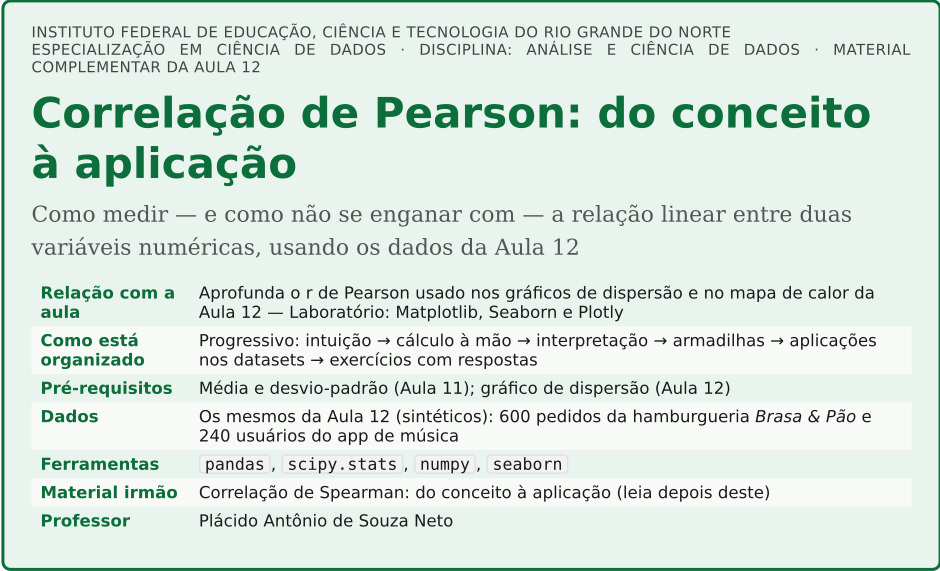

### Objetivos de aprendizagem

Ao final deste material, espera-se que o estudante seja capaz de:

- Explicar o que o coeficiente de Pearson mede (força e sentido de uma relação linear ) e o que ele não mede. 1.
- Calcular o r à mão, passo a passo, a partir das médias, dos desvios e da covariância - e conferir em Python. 2.
- Interpretar o valor de r, o r² e a inclinação da reta de regressão no contexto dos dados. 3.
- Reconhecer as armadilhas: relações não lineares, outliers, restrição de amplitude, variáveis de confusão e variância zero. 4.
- Aplicar a análise completa - gráfico, r, intervalo de confiança, subgrupos e correlação parcial - aos datasets da aula. 5.

### Como estudar este material

| Nível | Seções | Você vai… |
|----------------|----------|-----------------------------------------------------------------------------------|
| 1 · Intuição | 1 e 2 | enxergar associação positiva, negativa e nula, e entender a ideia dos quadrantes |
| 2 · Cálculo | 3 a 5 | transformar a ideia em fórmula, calcular o r de 8 pedidos à mão e ler o resultado |
| 3 · Armadilhas | 6 a 11 | ver quando o r engana e como se proteger |
| 4 · Aplicações | 12 a 16 | fazer a análise completa nos dois datasets, até a correlação parcial |
| 5 · Prática | Parte IV | resolver 8 exercícios progressivos (respostas no Apêndice B) |

| SOBRE OS DADOS |
|---------------------------------------------------------------------------------------------------------------------------|
| Os dois conjuntos são sintéticos (gerados por gerar_dados.py , no pacote da Aula 12). |
| Delivery: 600 pedidos com distância, tempo de entrega, taxa, itens, valor, avaliação (1- |
| 5), bairro, veículo, chuva e turno. App de música: 240 usuários com idade, plano |
| (Gratuito/Premium), horas ouvidas por semana, playlists, anúncios por semana e satisfação (0-10). Nenhum registro é real. |

### Parte I - Intuição e conceito

Do gráfico de dispersão à fórmula do r

### 1. Associação entre duas variáveis NÍVEL 1

Duas variáveis numéricas estão associadas quando conhecer o valor de uma ajuda a prever a outra. O primeiro passo é sempre o gráfico de dispersão : cada ponto é uma observação, com uma variável no eixo x e a outra no eixo y. Três padrões básicos aparecem nos dados da aula:

Figura 1 - Associação positiva (pedidos mais distantes demoram mais), negativa (usuários mais velhos ouvem menos) e praticamente nula (a distância não diz nada sobre o valor do pedido).

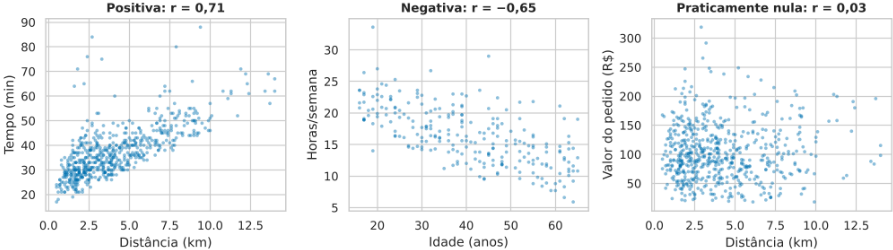

- Positiva: quando x cresce, y tende a crescer (nuvem 'subindo'). ·
- Negativa: quando x cresce, y tende a diminuir (nuvem 'descendo'). ·
- Nula: a nuvem não tem inclinação; x não ajuda a prever y. ·

O coeficiente de correlação de Pearson (r) resume em um único número, entre -1 e +1, o sentido (sinal) e a força (distância até ±1) dessa tendência - desde que ela seja aproximadamente uma linha reta .

### 2. A ideia dos quadrantes NÍVEL 1

Como transformar "a nuvem sobe" em número? Trace uma linha vertical na média de x (x̄) e uma horizontal na média de y (ȳ). O gráfico fica dividido em quatro quadrantes. Para cada ponto, calcule o desvio de cada variável em relação à sua média e multiplique os dois:

- ponto acima e à direita (desvios + e +) ou abaixo e à esquerda (- e -) → produto positivo : 'concorda' com uma relação positiva; ·
- ponto acima e à esquerda ou abaixo e à direita (sinais opostos) → produto negativo : 'concorda' com uma relação negativa. ·

Figura 2 - Oito pedidos de até 3 km. Verdes: produto dos desvios positivo (quadrantes II e III); laranja: produto negativo (I e IV). Há mais pontos verdes, e eles estão mais longe do centro.

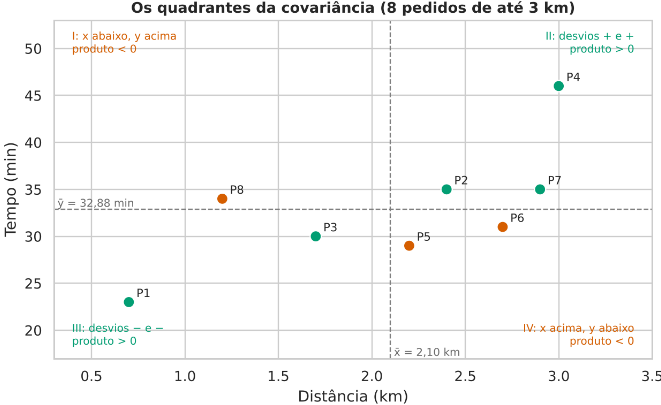

Somando todos os produtos, o resultado será positivo se predominarem os pontos dos quadrantes II e III, negativo se predominarem os de I e IV, e próximo de zero se eles se equilibrarem. Essa soma (dividida por n - 1) é a covariância .

### 3. Da covariância ao r: padronizar NÍVEL 2

<!-- formula-not-decoded -->

A covariância tem um problema: ela depende das unidades . Medir a distância em metros em vez de quilômetros multiplica a covariância por 1.000, sem mudar em nada a relação. Por isso não dá para dizer se uma covariância de 3,8 é 'grande' ou 'pequena'.

A solução é padronizar : dividir pela variabilidade de cada variável (os desvios-padrão s x e s y ). O resultado não tem unidade e fica sempre entre -1 e +1:

<!-- formula-not-decoded -->

em que z = (valor - média) / desvio-padrão é o escore padronizado de cada observação

A segunda forma mostra o que o r realmente é: praticamente a média dos produtos dos escores-z (a soma é dividida por n - 1). Cada ponto contribui com o quanto ele está, ao mesmo tempo, acima (ou abaixo) da média em x e em y, medido em desvios-padrão.

### 4. Calculando à mão: 8 pedidos NÍVEL 2

Vamos refazer a conta para os 8 pedidos da Figura 2 (x = distância, y = tempo).

- 1 Médias: x̄ = 16,8 / 8 = 2,10 km ; ȳ = 263 / 8 = 32,875 min .
- 2 Desvios e produtos, linha a linha:

| Ponto | Pedido | x (km) | y (min) | x - x̄ | y - ȳ | (x - x̄)(y - ȳ) | z x | z y | z x ·z y |
|---------|----------|----------|-----------|----------|---------|-------------------|-------|-------|------------|
| P1 | 50 | 0,7 | 23 | -1,40 | -9,88 | 13,83 | -1,68 | -1,49 | 2,51 |
| P2 | 82 | 2,4 | 35 | 0,30 | 2,12 | 0,64 | 0,36 | 0,32 | 0,12 |
| P3 | 569 | 1,7 | 30 | -0,40 | -2,88 | 1,15 | -0,48 | -0,43 | 0,21 |
| P4 | 159 | 3,0 | 46 | 0,90 | 13,12 | 11,81 | 1,08 | 1,98 | 2,15 |
| P5 | 149 | 2,2 | 29 | 0,10 | -3,88 | -0,39 | 0,12 | -0,59 | -0,07 |
| P6 | 504 | 2,7 | 31 | 0,60 | -1,88 | -1,13 | 0,72 | -0,28 | -0,20 |
| P7 | 16 | 2,9 | 35 | 0,80 | 2,12 | 1,70 | 0,96 | 0,32 | 0,31 |
| P8 | 287 | 1,2 | 34 | -0,90 | 1,12 | -1,01 | -1,08 | 0,17 | -0,18 |
| Soma | | 16,8 | 263 | 0,00 | 0,00 | 26,60 | 0,00 | 0,00 | 4,83 |

- 3 Covariância: 26,60 / (8 - 1) = 3,80 km·min.
- 4 Desvios-padrão: s x = 0,8315 km e s y = 6,6211 min.
- 5 Coeficiente: r = 3,80 / (0,8315 × 6,6211) = 0,690 . Pela outra fórmula: Σ z x z y / 7 = 4,831 / 7 = 0,690.
- 6 Conferência em Python:

```
import numpy as np, pandas as pd
from scipy import stats
x = np.array([0.7, 2.4, 1.7, 3.0, 2.2, 2.7, 2.9, 1.2])
y = np.array([23, 35, 30, 46, 29, 31, 35, 34])
cov = ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)   # 3,80
r = cov / (x.std(ddof=1) * y.std(ddof=1))                      # 0,690
stats.pearsonr(x, y).statistic                                 # 0,690
np.corrcoef(x, y)[0, 1]                                        # 0,690
pd.Series(x).corr(pd.Series(y))                                # 0,690 (padrão do pandas:
Pearson)
```

### ATENÇÃO AO DDOF

O pandas usa n - 1 no desvio-padrão ( ddof=1 ), mas o np.std usa n por padrão. Na fórmula do r, o importante é usar o mesmo denominador na covariância e nos desvios - por isso np.corrcoef e stats.pearsonr dão o mesmo resultado.

### 5. Lendo o valor de r e o r² NÍVEL 2

Figura 3 - Como 'parece' cada valor de r (120 pontos simulados em cada painel). Repare que r = 0,4 já é uma nuvem bem espalhada.

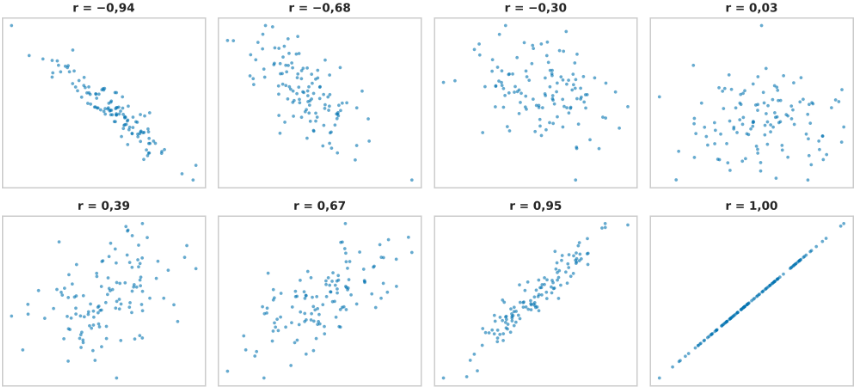

Sinal = sentido da relação. Valor absoluto = quão perto os pontos estão de uma reta. Uma referência comum (não é uma regra fixa; depende da área):

| &#124;r&#124; | Leitura usual | Exemplo nos dados da aula |
|-----------------|---------------------------|-----------------------------------------------------------------|
| 0,00 - 0,19 | muito fraca / desprezível | distância × valor do pedido (r = 0,03) |
| 0,20 - 0,39 | fraca | idade × satisfação (r = 0,20) |
| 0,40 - 0,59 | moderada | distância × avaliação (r = -0,43); playlists × horas (r = 0,54) |
| 0,60 - 0,79 | forte | distância × tempo (r = 0,71); idade × horas (r = -0,65) |
| 0,80 - 1,00 | muito forte | itens × valor (r = 0,92); anúncios × satisfação (r = -0,82) |

O r² (coeficiente de determinação) é a proporção da variação de y que a reta "explica" a partir de x. Para distância × tempo, r = 0,71 e r² = 0,51: cerca de 51% da variação do tempo de entrega acompanha a distância; os outros 49% vêm de chuva, turno, veículo, atrasos etc.

### R NÃO É PORCENTAGEM

Um erro frequente é ler r = 0,71 como '71% de relação'. A proporção explicada é o r² (51%). E r = 0,4 não é 'metade' de r = 0,8: em termos de r², 0,16 contra 0,64 - quatro vezes menos.

### Parte II - Armadilhas: quando o r engana

O r é um resumo - e todo resumo esconde coisas

### 6. Pearson mede só relação linear NÍVEL 3

O quarteto de Anscombe (1973) tem quatro conjuntos com médias, variâncias, reta de regressão e r = 0,82 iguais . Os gráficos são completamente diferentes:

Figura 4 - Quarteto de Anscombe. I: relação linear (o r descreve bem). II: curva (relação perfeita, mas não linear). III: linear com um outlier. IV: sem relação, com um único ponto criando o r.

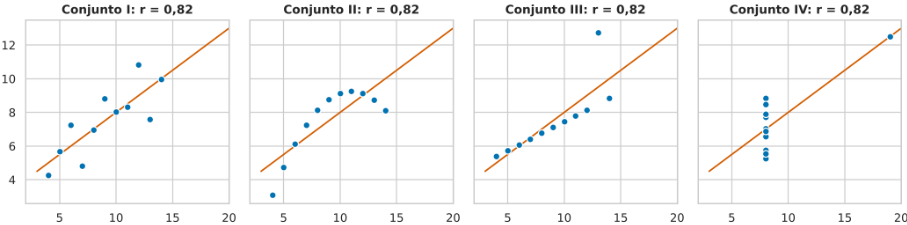

Lição: nunca reporte um r sem olhar o gráfico de dispersão. Se a relação for curva mas sempre crescente (ou sempre decrescente), use o coeficiente de Spearman (material irmão). Se for em "U", nenhum dos dois coeficientes resume bem a relação.

### 7. Outliers podem criar ou destruir uma correlação NÍVEL 3

Como o r usa os desvios em relação à média, um único ponto muito afastado pode dominar a soma dos produtos. Veja o que acontece com 12 pedidos de até 3 km quando acrescentamos um pedido:

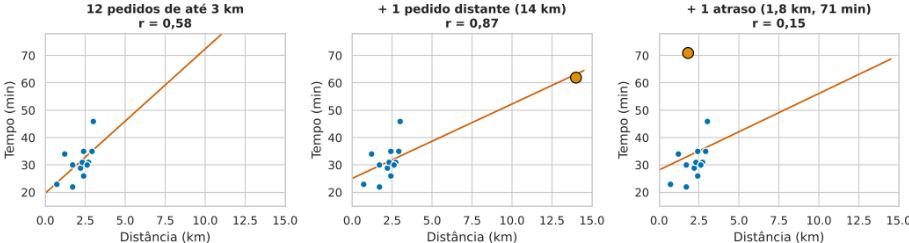

Figura 5 - O mesmo grupo de 12 pedidos (azul) com um ponto a mais (laranja).

| Cenário | Pearson r | Spearman ρ (veja o material irmão) |
|-----------------------------|-------------|--------------------------------------|
| 12 pedidos de até 3 km | 0,58 | 0,61 |
| + 1 pedido distante (14 km) | 0,87 | 0,69 |
| + 1 atraso (1,8 km, 71 min) | 0,15 | 0,45 |

Um pedido distante, que até segue a tendência, faz o r saltar de 0,58 para 0,87 (o ponto 'puxa' a reta). Um único atraso faz o r cair para 0,15. O Spearman, que trabalha com postos, varia bem menos.

### O QUE FAZER COM OUTLIERS

- 1) Investigue: é erro de digitação ou um caso real (pedido trocado, endereço errado)?
- 2) Calcule o r com e sem o ponto e reporte os dois. 3) Considere o Spearman. Nunca apague um ponto só porque ele atrapalha o resultado.

### 8. Restrição de amplitude NÍVEL 3

O r depende da faixa de valores observada. Se olharmos só uma 'fatia' do eixo x, a parte previsível da variação diminui e o r cai - mesmo que a relação seja a mesma.

Figura 6 - Todos os pedidos: r = 0,71. Só os pedidos de até 3 km: r = 0,42.

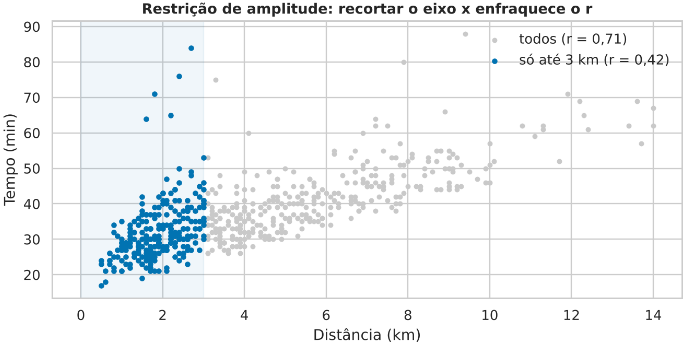

Isso explica um resultado curioso da aula: a correlação distância × tempo é 0,53 nas entregas de bicicleta e 0,77 nas de moto . A bicicleta não é "menos afetada" pela distância - ela só faz entregas de até 3 km, uma faixa estreita. Comparando a mesma faixa (até 3 km), a moto tem r = 0,30.

### 9. Variável de confusão: correlação não é causalidade NÍVEL 3

Uma terceira variável pode criar, aumentar ou esconder uma correlação. No app de música, o plano faz as duas coisas:

Figura 7 - À esquerda, a correlação geral é inflada pelo plano. À direita, a correlação geral é atenuada por ele.

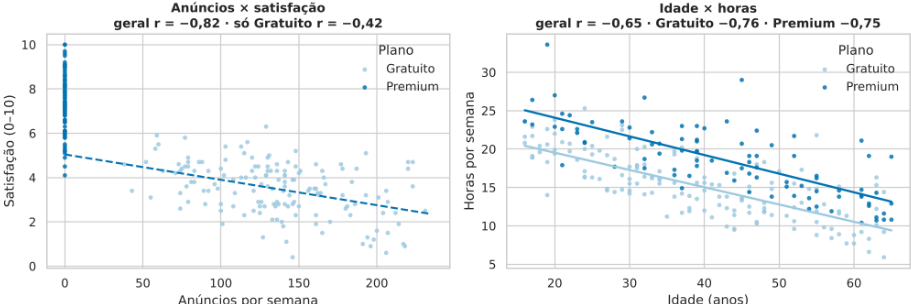

- Anúncios × satisfação: r geral = -0,82. Mas os usuários Premium têm zero anúncios e satisfação alta - eles formam a coluna à esquerda e "puxam" a reta. Dentro do plano Gratuito, r = -0,42: a relação existe, mas é bem mais fraca. ·

- Idade × horas: r geral = -0,65, mas dentro de cada plano o r é mais forte (-0,76 e -0,75). Usuários mais velhos tendem a ser Premium, e Premium ouve mais; misturar os grupos 'dilui' a relação. ·

Mesmo um r forte não prova que x causa y. Causalidade exige desenho de estudo (experimento, controle de variáveis), não só correlação.

### 10. Variância zero e variáveis redundantes NÍVEL 3

Variância zero: no plano Premium, anuncios\_semana vale 0 para todos. Como s x = 0, a fórmula divide por zero e o r não existe (o pandas devolve NaN e o SciPy emite um aviso). Não é "correlação zero" - é correlação indefinida.

Redundância: distância × taxa de entrega tem r = 0,99, porque a taxa é calculada a partir da distância. Variáveis quase idênticas não trazem informação nova; em modelos (Unidade 4) uma delas costuma ser descartada.

### 11. O r é uma estimativa: p-valor e intervalo de confiança NÍVEL 3

Os 600 pedidos são uma amostra; outro período daria outro r. O scipy.stats.pearsonr devolve, além do r:

- o p-valor do teste "a correlação na população é zero?" - p pequeno (ex.: &lt; 0,05) indica que um r desse tamanho dificilmente apareceria por acaso; ·
- o intervalo de confiança de 95% (via transformação z de Fisher) - a faixa de valores plausíveis para a correlação populacional. ·

In [ ]:
res = stats.pearsonr(df["distancia_km"], df["tempo_entrega_min"])
res.statistic                  # r = 0,713
res.pvalue                     # p ≈ 4e-94  (praticamente zero)
res.confidence_interval()      # IC 95%: (0,671 ; 0,750)

### SIGNIFICATIVO NÃO É O MESMO QUE FORTE

Com amostras grandes, até um r = 0,10 pode ter p &lt; 0,05. O p-valor diz se a correlação provavelmente existe ; o valor de r e o IC dizem se ela é importante . Com amostras pequenas (como os 8 pedidos da Seção 4), o IC fica muito largo.

### Parte III - Aplicações nos datasets da aula

A análise completa, do gráfico à correlação parcial

### 12. Distância × tempo, do começo ao fim NÍVEL 4

Um roteiro completo para um par de variáveis:



1 Gráfico (dispersão) - a relação é aproximadamente linear? Há outliers? 2 r e IC 95% . 3 r² e a reta . 4 Subgrupos : a relação se mantém nas categorias importantes?



Figura 8 - A relação é aproximadamente linear, com alguns atrasos excepcionais acima da reta.

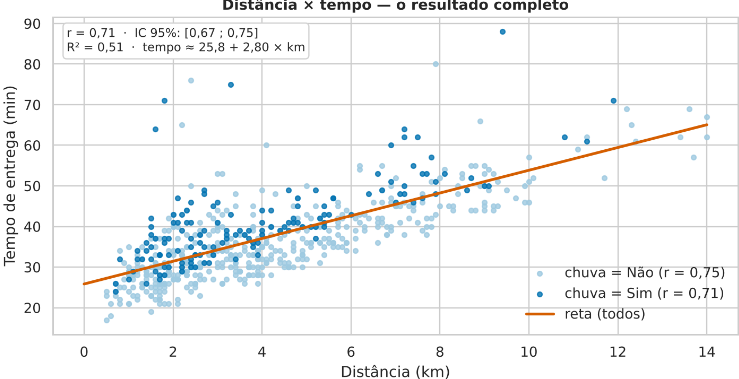

- r = 0,713 , IC 95% [0,671 ; 0,750] - relação positiva forte, estimada com boa precisão (n = 600). ·
- r² = 0,51 - a distância acompanha metade da variação do tempo. ·
- A inclinação da reta se relaciona com o r: b = r × s y / s x = 0,713 × 10,36 / 2,63 = 2,80 min por km . O r é a inclinação 'em desvios-padrão': se a distância sobe 1 desvio-padrão, o tempo sobe, em média, 0,71 desvio-padrão. ·
- Por subgrupo: sem chuva r = 0,75, com chuva r = 0,71. A chuva desloca a nuvem para cima (+ minutos), mas mantém a força da relação. ·

In [ ]:
for chuva, g in df.groupby("chuva"):
    print(chuva, round(g["distancia_km"].corr(g["tempo_entrega_min"]), 2))

### 13. A matriz de correlação NÍVEL 4

Com várias variáveis numéricas, calculamos o r de todos os pares de uma vez com df[colunas].corr() e o exibimos como mapa de calor (Aula 12).

Figura 9 - Matrizes de correlação de Pearson dos dois datasets.

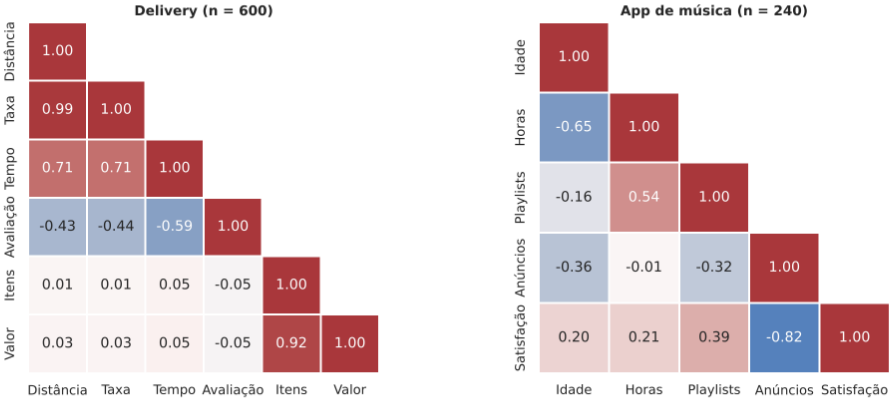

Como ler uma matriz, em ordem: (1) procure os |r| mais altos; (2) separe os 'óbvios' (taxa × distância, itens × valor: redundâncias ou definições) dos interessantes; (3) para cada par interessante, volte ao gráfico de dispersão e verifique linearidade, outliers e subgrupos - a matriz não mostra nada disso.

| Par | r | Leitura |
|-----------------------|-------|------------------------------------------------------------------------------------------------|
| Distância × taxa | 0,99 | redundante: a taxa é calculada pela distância |
| Itens × valor | 0,92 | esperado: mais itens, pedido mais caro |
| Distância × tempo | 0,71 | relação forte e linear (Seção 12) |
| Tempo × avaliação | -0,59 | entregas demoradas recebem notas menores - mas avaliação é ordinal (1-5): confira com Spearman |
| Valor × tempo | 0,05 | o tamanho do pedido quase não afeta o tempo |
| Anúncios × satisfação | -0,82 | muito forte, mas inflado pelo plano (Seção 9) |
| Idade × horas | -0,65 | forte; mais forte ainda dentro de cada plano |

### 14. Correlação parcial: controlando o plano NÍVEL 4

Na Seção 9 separamos os grupos à mão. A correlação parcial faz isso de forma geral: mede a relação entre x e y depois de remover o efeito de uma terceira variável z. A ideia tem dois passos:

1 Explique x por z com uma regressão e guarde o que sobra (os resíduos de x); faça o mesmo com y. 2 Calcule o Pearson entre os dois resíduos.

Há também uma fórmula direta, a partir das três correlações simples:

<!-- formula-not-decoded -->

Com x = anúncios, y = satisfação e z = plano (Premium = 1, Gratuito = 0): r xy = -0,821, r xz = -0,883 e r yz = 0,835, o que dá r xy·z = -0,325 .

In [ ]:
m["premium"] = (m["plano"] == "Premium").astype(int)

def residuo(alvo, controle):
    b1, b0 = np.polyfit(controle, alvo, 1)      # reta alvo ~ controle
    return alvo - (b0 + b1 * controle)

r_parcial = stats.pearsonr(residuo(m["anuncios_semana"], m["premium"]),
                           residuo(m["satisfacao"], m["premium"])).statistic   # −0,325

Leitura: de -0,82 (geral) para -0,32 (controlando o plano). A maior parte da correlação original vinha da diferença entre os planos; descontado o plano, sobra uma relação negativa fraca a moderada entre anúncios e satisfação.

### 15. Pearson e a reta de regressão NÍVEL 4

Correlação e regressão linear simples são duas faces da mesma conta:

| | Correlação (r) | Regressão (y = b₀ + b₁·x) |
|----------|--------------------------------|------------------------------------------------------|
| Pergunta | quão forte é a relação linear? | quanto y muda, em média, quando x aumenta 1 unidade? |
| Simetria | simétrica: r(x, y) = r(y, x) | não é simétrica: prever y por x ≠ prever x por y |
| Unidade | sem unidade, de -1 a 1 | na unidade de y por unidade de x (2,80 min/km) |
| Ligação | r² = proporção explicada | b₁ = r · s y / s x |

Na Unidade 4 (Aprendizado de Máquina) a regressão volta, com várias variáveis ao mesmo tempo. A matriz de correlação é a primeira ferramenta para escolher quais variáveis usar e quais são redundantes.

### 16. Roteiro de análise de correlação (checklist)

- As duas variáveis são numéricas (contínuas ou discretas com muitos valores)? Se uma for ordinal, prefira Spearman. 1.
- Faça o gráfico de dispersão : a relação é aproximadamente linear? 2.
- Procure outliers ; calcule o r com e sem eles. 3.
- Calcule r, IC 95% e p-valor ; reporte também o n . 4.
- Interprete sentido, força e r² no contexto (com unidades). 5.
- Verifique subgrupos e possíveis variáveis de confusão ; se necessário, use a correlação parcial. 6.
- Não conclua causalidade a partir da correlação. 7.

### Parte IV - Exercícios progressivos

Do conceitual à aplicação; respostas no Apêndice B

### Exercício 1 NÍVEL 1

Para cada valor de r, diga o sentido e a força da relação: (a) r = -0,85; (b) r = 0,12; (c) r = 0,63; (d) r = -0,35.

### Exercício 2 NÍVEL 1

Um gráfico de dispersão tem a maioria dos pontos nos quadrantes I e IV (acima e à esquerda; abaixo e à direita das médias). O que você espera do sinal da covariância e do r?

### Exercício 3 NÍVEL 2

Calcule à mão o r de Pearson para x = distância (km) = 1, 2, 3, 4, 5 e y = tempo (min) = 20, 26, 27, 33, 34. Confira com np.corrcoef .

### Exercício 4 NÍVEL 2

No app de música, idade × horas tem r = -0,65. Calcule e interprete o r².

### Exercício 5 NÍVEL 3

Por que a correlação distância × tempo é menor nas entregas de bicicleta do que nas de moto? Isso significa que a distância afeta menos a bicicleta?

### Exercício 6 NÍVEL 3

Ao calcular anuncios\_semana × satisfacao apenas para usuários Premium, o pandas devolve NaN . Por quê?

### Exercício 7 NÍVEL 4

Usando o dataset de delivery, calcule em Python o r entre itens e valor do pedido e entre valor do pedido e tempo de entrega. Interprete os dois resultados.

### Exercício 8 NÍVEL 4

No app de música, a correlação geral anúncios × satisfação é -0,82, a correlação só no plano Gratuito é -0,42 e a correlação parcial controlando o plano é -0,32. Explique, em um parágrafo para um gestor do aplicativo, o que esses três números dizem.

### Apêndice A - Colinha de Pearson em Python

In [ ]:
import numpy as np, pandas as pd, seaborn as sns
from scipy import stats

df["x"].corr(df["y"])                          # r (pandas: Pearson é o padrão)
np.corrcoef(df["x"], df["y"])[0, 1]            # r (NumPy)
res = stats.pearsonr(df["x"], df["y"])         # r + p-valor + IC
res.statistic, res.pvalue, res.confidence_interval()
res.statistic ** 2                             # r²

df[colunas].corr()                             # matriz de correlação
df.groupby("grupo")[["x", "y"]].corr()         # matriz por subgrupo

reg = stats.linregress(df["x"], df["y"])       # reta: reg.intercept + reg.slope * x
sns.regplot(data=df, x="x", y="y")             # dispersão + reta + IC 95% da reta
sns.heatmap(df[colunas].corr(), annot=True, fmt=".2f",
            cmap="vlag", center=0, vmin=-1, vmax=1)

### Apêndice B - Respostas dos exercícios

1. (a) negativa muito forte; (b) positiva muito fraca/desprezível; (c) positiva forte; (d) negativa fraca.
2. Nos quadrantes I e IV os desvios têm sinais opostos, então os produtos são negativos: covariância negativa e r negativo (relação decrescente).
4. r² = (-0,65)² ≈ 0,42: cerca de 42% da variação das horas ouvidas acompanha a idade; o sinal negativo indica que usuários mais velhos ouvem menos, em média.
5. Restrição de amplitude (Seção 8): a bicicleta só faz entregas de até 3 km, uma faixa estreita de x. Com pouca variação em x, o r fica menor. Não significa que a distância afete menos a bicicleta; na mesma faixa (até 3 km) a moto também tem r baixo (0,30).
6. Todos os Premium têm 0 anúncios: o desvio-padrão de x é zero e a fórmula do r divide por zero. A correlação é indefinida (não é zero).
7. df["itens"].corr(df["valor\_pedido"]) = 0,92 (muito forte e esperado: o valor é praticamente a soma dos itens). df["valor\_pedido"].corr(df["tempo\_entrega\_min"]) = 0,05 (desprezível: pedidos maiores não demoram mais para chegar).

```
3. x̄ = 3; ȳ = 28. Desvios de x: -2, -1, 0, 1, 2; de y: -8, -2, -1, 5, 6. Produtos: 16, 2, 0, 5, 12 → soma = 35; cov = 35/4 = 8,75. Σ(x - x̄)² = 10 → s x = √(10/4) = 1,581; Σ(y - ȳ)² = 64 + 4 + 1 + 25 + 36 = 130 → s y  = √(130/4) = 5,701. r = 8,75 / (1,581 × 5,701) = 0,971 . np.corrcoef([1,2,3,4,5], [20,26,27,33,34])[0, 1] → 0,971.
```

8. Exemplo: "Olhando todos os usuários juntos, parece que os anúncios derrubam fortemente a satisfação (r = -0,82). Mas boa parte disso vem de comparar dois públicos diferentes: os assinantes Premium não ouvem anúncios e já são mais satisfeitos. Entre os usuários do plano gratuito, mais anúncios continuam associados a menos satisfação, porém de forma moderada (r = -0,42); controlando o plano estatisticamente, r = -0,32. Reduzir anúncios pode ajudar, mas o efeito esperado é bem menor do que o número geral sugere - e só um teste (por exemplo, A/B) mostraria causalidade."

### Referências

- ANSCOMBE, F. J. Graphs in statistical analysis. The American Statistician , v. 27, n. 1, p. 17-21, 1973. ·
- BUSSAB, W. O.; MORETTIN, P . A. Estatística Básica . 9. ed. São Paulo: Saraiva, 2017 - cap. sobre análise bidimensional. ·
- FIELD, A. Descobrindo a estatística usando o SPSS . 2. ed. Porto Alegre: Artmed, 2009 - cap. Correlação. ·
- BRUCE, P.; BRUCE, A.; GEDECK, P . Estatística prática para cientistas de dados . 2. ed. Alta Books, 2021. ·
- SciPy - documentação de scipy.stats.pearsonr ; pandas - DataFrame.corr . ·

---
## Material complementar — Correlação de Spearman (PDF)

> Material complementar da Aula 12, progressivo, sobre o coeficiente de correlação de Spearman: relações monotônicas, postos e empates, cálculo à mão (sem e com empates), Spearman × Pearson (outliers, variáveis ordinais, curvas monotônicas e relações não monotônicas), aplicações nos datasets da aula (matrizes, subgrupos, dados agregados) e um quadro para decidir entre Pearson e Spearman. Inclui 8 exercícios com respostas.

> Convertido de [`Aula12_Complementar_Correlacao_Spearman.pdf`](Aula12_Complementar_Correlacao_Spearman.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS · DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS · MATERIAL COMPLEMENTAR DA AULA 12

### Correlação de Spearman: do conceito à aplicação

Correlação com postos: para relações monotônicas, variáveis ordinais e dados com outliers, usando os dados da Aula 12

| Relação com a aula | Complementa a Aula 12 - Laboratório: Matplotlib, Seaborn e Plotly (gráfico de dispersão e mapa de calor) |
|----------------------|--------------------------------------------------------------------------------------------------------------------------------------------------|
| Como está organizado | Progressivo: por que outro coeficiente → postos → cálculo à mão (sem e com empates) → Spearman × Pearson → aplicações → exercícios com respostas |
| Pré-requisitos | Material complementar de Pearson (leia antes); mediana e quartis (Aula 11) |
| Dados | Os mesmos da Aula 12 (sintéticos): 600 pedidos da hamburgueria Brasa & Pão e 240 usuários do app de música |
| Ferramentas | pandas ( rank , corr(method="spearman") ), scipy.stats.spearmanr , seaborn |
| Professor | Plácido Antônio de Souza Neto |

### Objetivos de aprendizagem

Ao final deste material, espera-se que o estudante seja capaz de:

- Explicar o que é uma relação monotônica e por que, às vezes, o Pearson não é a melhor medida. 1.
- Transformar valores em postos , inclusive com empates (posto médio). 2.
- Calcular o ρ de Spearman à mão - pela fórmula das diferenças de postos e como Pearson dos postos - e conferir em Python. 3.
- Comparar Spearman e Pearson e escolher o coeficiente adequado ao tipo de variável e à forma da relação. 4.
- Aplicar o Spearman aos datasets da aula: variáveis ordinais, subgrupos, matrizes e dados agregados. 5.

### Como estudar este material

| Nível | Seções | Você vai… |
|----------------|----------|---------------------------------------------------------------------------------------|
| 1 · Motivação | 1 e 2 | ver três situações em que o Pearson não basta e entender o que é monotonicidade |
| 2 · Cálculo | 3 a 6 | transformar valores em postos, calcular o ρ à mão (sem e com empates) e interpretá-lo |
| 3 · Comparação | 7 a 10 | comparar Spearman e Pearson: outliers, variáveis ordinais e relações não monotônicas |
| 4 · Aplicações | 11 a 15 | usar o Spearman nos dois datasets, em subgrupos, matrizes e dados agregados |
| 5 · Prática | Parte IV | resolver 8 exercícios progressivos (respostas no Apêndice B) |

### SOBRE OS DADOS

Os mesmos conjuntos sintéticos da Aula 12: 600 pedidos de delivery (distância, tempo, taxa, itens, valor, avaliação de 1 a 5 , bairro, veículo, chuva, turno) e 240 usuários de um app de música (idade, plano, horas por semana, playlists, anúncios por semana e satisfação de 0 a 10). Nenhum registro é real.

### Parte I - Conceito e cálculo

Trocar valores por posições: a ideia central do Spearman

### 1. Por que outro coeficiente? NÍVEL 1

- O Pearson mede quão bem os pontos se ajustam a uma reta e usa os valores numéricos diretamente. Isso cria três situações delicadas:
- A relação é crescente (ou decrescente), mas não é uma reta. Ex.: as músicas favoritadas crescem rápido nos primeiros dias de uso e depois se estabilizam. 1.
- A variável é ordinal. Ex.: a avaliação de 1 a 5 do delivery. A diferença entre 1 e 2 estrelas não é necessariamente "igual" à diferença entre 4 e 5 - só a ordem é confiável. 2.
- Há outliers. Ex.: um pedido trocado que levou 71 minutos para percorrer 1,8 km. 3.

O coeficiente de correlação de Spearman (ρ, letra grega "rô") resolve as três situações com uma única ideia: em vez dos valores, usar as posições (postos) de cada observação.

Figura 1 - Linear: os dois coeficientes concordam. Monotônica não linear: o ρ (0,89) capta melhor a relação que o r (0,84). Não monotônica (sobe e desce): nenhum dos dois serve.

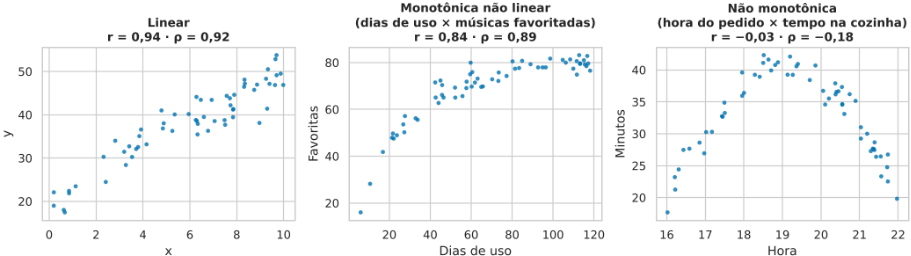

### 2. Relação monotônica NÍVEL 1

Uma relação é monotônica crescente quando, à medida que x aumenta, y nunca diminui (tende a aumentar) - mas não precisa aumentar sempre na mesma taxa. É monotônica decrescente quando y tende sempre a diminuir. Toda relação linear é monotônica, mas nem toda relação monotônica é linear.

| Forma da relação | Exemplo | Pearson (r) | Spearman (ρ) |
|-------------------------------------------------------|----------------------------------------------------|---------------|----------------|
| Linear | distância × tempo de entrega | adequado | adequado |
| Monotônica não linear (curva que só sobe ou só desce) | dias de uso × músicas favoritadas | subestima | adequado |
| Não monotônica (sobe e desce) | hora do pedido × tempo na cozinha (pico no jantar) | inadequado | inadequado |

O ρ responde: "quando x aumenta, y tende a aumentar (ou diminuir) de forma consistente?" . O r responde: "os pontos estão próximos de uma reta?" .

### 3. Postos (ranks) NÍVEL 2

Ordenar os valores do menor para o maior e substituir cada um pela sua posição: o menor recebe posto 1, o seguinte posto 2, e assim por diante. Cada variável é ordenada separadamente .

Empates: valores iguais recebem a média das posições que ocupariam. Em [3, 5, 4, 4, 2] : o 2 fica com posto 1; o 3 com posto 2; os dois "4" ocupariam as posições 3 e 4, então ambos recebem (3 + 4) / 2 = 3,5 ; o 5 fica com posto 5.

In [ ]:
import pandas as pd
pd.Series([3, 5, 4, 4, 2]).rank()            # [2.0, 5.0, 3.5, 3.5, 1.0]  (padrão: posto médio)

In [ ]:
pd.Series([3, 5, 4, 4, 2]).rank(ascending=False)  # ordem inversa, se precisar

### O QUE SE PERDE E O QUE SE GANHA

Ao trocar valores por postos perdemos a distância entre os valores (88 min e 50 min viram apenas "1º e 2º mais demorados"). Em troca, o resultado fica imune à escala, a curvas monotônicas e a valores extremos.

### 4. Calculando à mão (sem empates): 6 usuários NÍVEL 2

Seis usuários do app de música: x = idade, y = horas ouvidas por semana. Não há valores repetidos.

1 Postos de cada variável (1 = menor). 2 Diferença d = posto(x) - posto(y) e seu quadrado.

| Usuário | Idade | Posto idade | Horas/sem. | Posto horas | d | d² |
|-------------|---------|---------------|--------------|---------------|-----|------|
| U1 (id 45) | 29 | 3 | 22,5 | 5 | -2 | 4 |
| U2 (id 18) | 48 | 6 | 11,8 | 1 | +5 | 25 |
| U3 (id 170) | 16 | 1 | 23,6 | 6 | -5 | 25 |
| U4 (id 100) | 43 | 5 | 16,9 | 3 | +2 | 4 |
| U5 (id 136) | 33 | 4 | 16,4 | 2 | +2 | 4 |
| U6 (id 234) | 20 | 2 | 19,4 | 4 | -2 | 4 |
| Soma | | | | | 0 | 66 |



### 3 Fórmula de Spearman (válida quando não há empates ):

<!-- formula-not-decoded -->

ρ = 1 - 6 × 66 / [6 × (36 - 1)] = 1 - 396 / 210 = -0,886 . Para comparar, o Pearson desses mesmos valores é r = -0,849.

Por que a fórmula funciona? Se os postos coincidissem (o mais novo é quem ouve menos, e assim por diante), todos os d seriam 0 e ρ = 1. Se fossem exatamente invertidos, Σd² atingiria o máximo e ρ = -1. Aqui os postos estão quase invertidos: relação negativa forte.

In [ ]:
from scipy import stats
idade = [29, 48, 16, 43, 33, 20]
horas = [22.5, 11.8, 23.6, 16.9, 16.4, 19.4]
stats.spearmanr(idade, horas).statistic    # −0,886

### 5. Com empates: Spearman = Pearson dos postos NÍVEL 2

A definição geral do ρ é simples: calcule os postos e aplique a fórmula de Pearson aos postos . A fórmula com Σd² é apenas um atalho que dá o mesmo resultado quando não há empates. Com empates, ela erra.

Oito pedidos do delivery (avaliação 1-5 × tempo). As avaliações em ordem são 3, 3, 4, 4, 4, 5, 5, 5: os três "4" ocupariam as posições 3, 4 e 5 e recebem posto médio 4; os três "5" ocupariam 6, 7 e 8 e recebem 7; os dois "3" recebem 1,5.

| Pedido | Avaliação | Posto avaliação | Tempo (min) | Posto tempo |
|----------|-------------|-------------------|---------------|---------------|
| 196 | 4 | 4 | 45 | 6,5 |
| 156 | 5 | 7 | 31 | 4 |
| 41 | 3 | 1,5 | 45 | 6,5 |
| 213 | 4 | 4 | 38 | 5 |
| 53 | 5 | 7 | 24 | 1 |
| 530 | 4 | 4 | 29 | 3 |
| 112 | 3 | 1,5 | 51 | 8 |
| 259 | 5 | 7 | 28 | 2 |

Pearson dos postos: ρ = -0,843 - é o que stats.spearmanr calcula. A fórmula Σd² aplicada aos mesmos postos daria -0,732: um erro grande, porque há muitos empates.

In [ ]:
p8["posto_aval"] = p8["avaliacao"].rank()            # posto médio nos empates
p8["posto_tempo"] = p8["tempo_entrega_min"].rank()
stats.pearsonr(p8["posto_aval"], p8["posto_tempo"]).statistic   # −0,843
stats.spearmanr(p8["avaliacao"], p8["tempo_entrega_min"]).statistic  # −0,843
p8["avaliacao"].corr(p8["tempo_entrega_min"], method="spearman")   # −0,843

Figura 2 - Os 600 pedidos em valores (esquerda) e em postos (direita). O ρ de Spearman (0,72) é exatamente o Pearson calculado no gráfico da direita.

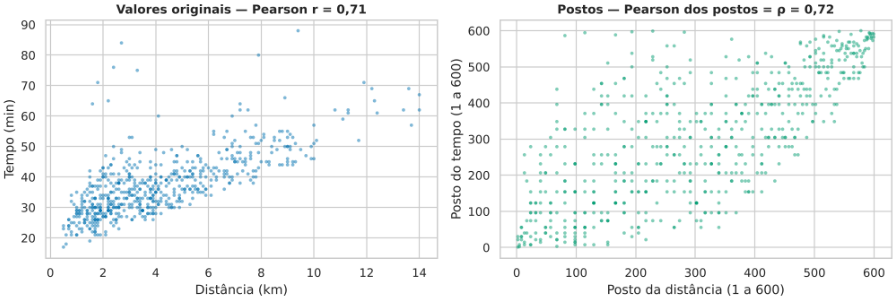

### 6. Interpretando o ρ NÍVEL 2

- Varia de -1 a +1 , com a mesma leitura de sinal e força do Pearson (a tabela de faixas do material de Pearson também serve como referência). ·

- ρ = +1: a ordem de x é exatamente a ordem de y (relação monotônica crescente perfeita), mesmo que a curva não seja uma reta. ·
- ρ = -1: a ordem é exatamente inversa. ·
- ρ ≈ 0: não há tendência monotônica - o que não exclui uma relação em "U" ou "∩". ·
- O ρ² não deve ser lido como "porcentagem da variação explicada" dos valores originais; ele se refere aos postos. Reporte o ρ. ·

### Parte II - Spearman × Pearson

Quando os dois concordam, quando discordam e por quê

### 7. Robustez a outliers NÍVEL 3

Em postos, um valor extremo é apenas "o maior" (ou "o menor"): sua distância até os outros desaparece. Por isso o ρ muda pouco quando um outlier entra ou sai.

| Cenário (pedidos de até 3 km) | Pearson r | Spearman ρ | Variação de r | Variação de ρ |
|---------------------------------|-------------|--------------|-----------------|-----------------|
| 12 pedidos de até 3 km | 0,58 | 0,61 | - | - |
| + 1 pedido distante (14 km) | 0,87 | 0,69 | +0,29 | +0,08 |
| + 1 atraso (1,8 km, 71 min) | 0,15 | 0,45 | -0,43 | -0,16 |

Figura 3 - O pedido atrasado (laranja) está longe de todos os outros nos valores, mas nos postos ele é só o posto 13 do tempo.

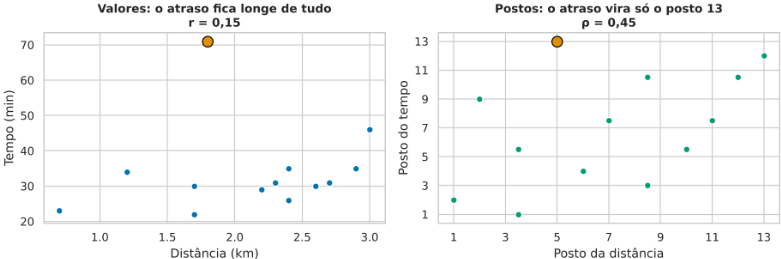

### ROBUSTO NÃO É IMUNE

O ρ também caiu com o atraso (de 0,61 para 0,45): com só 13 pontos, um posto fora do lugar ainda pesa. A robustez aumenta com o tamanho da amostra. E o Spearman não substitui a investigação do outlier.

### 8. Variáveis ordinais: a avaliação do cliente NÍVEL 3

A avaliação (1 a 5 estrelas) é ordinal : sabemos que 5 é melhor que 4, mas não que a "distância" entre 4 e 5 é igual à entre 1 e 2. O Pearson trata os números como medidas; o Spearman usa apenas a ordem - por isso é a escolha adequada para escalas de satisfação, notas por conceito, níveis de escolaridade etc.

Figura 4 - Tempo de entrega por nota recebida. Cada estrela a menos corresponde a entregas mais demoradas.

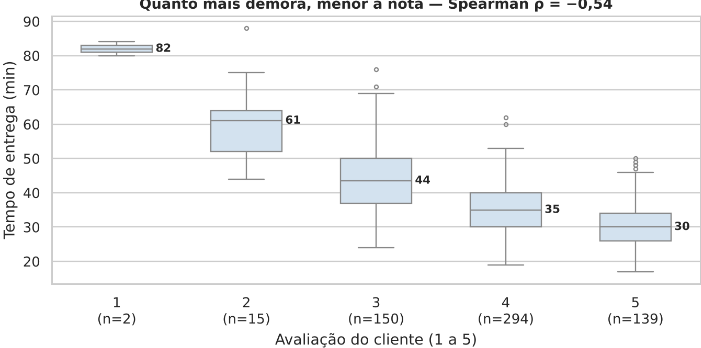

Avaliação × tempo: ρ = -0,537 (Pearson: -0,594). Avaliação × distância: ρ = -0,404 (Pearson: -0,435). Os valores são parecidos, mas só o ρ tem interpretação garantida para uma escala ordinal. Repare também nos empates : só existem 5 valores possíveis para 600 pedidos - 294 pedidos receberam nota 4 e dividem o mesmo posto médio.

### E O TAU DE KENDALL?

Com muitos empates ou amostras pequenas , outra opção é o τ (tau) de Kendall ( stats.kendalltau ), que compara todos os pares de observações e conta quantos estão "na mesma ordem". Ele costuma dar valores menores em módulo que o ρ e tem a mesma leitura de sinal.

### 9. Relações monotônicas não lineares NÍVEL 3

Na Figura 1 (centro), as músicas favoritadas crescem rápido no início e depois estabilizam. A relação é perfeitamente "consistente" - mais dias de uso nunca significam menos favoritas -, mas não é uma reta. O Pearson (0,84) penaliza a curvatura; o Spearman (0,89) mede justamente a consistência da ordem. Curvas desse tipo são comuns: aprendizagem, saturação de mercado, crescimento populacional, retornos decrescentes.

### 10. Limitação: relações não monotônicas NÍVEL 3

Spearman não resolve relações que sobem e depois descem. Um exemplo nos dados da aula: dia da semana (1 = segunda … 7 = domingo) × valor do pedido.

Figura 5 - O ticket médio sobe na sexta, sábado e domingo e é menor de segunda a quinta (com um pico na quarta). ρ = 0,18.

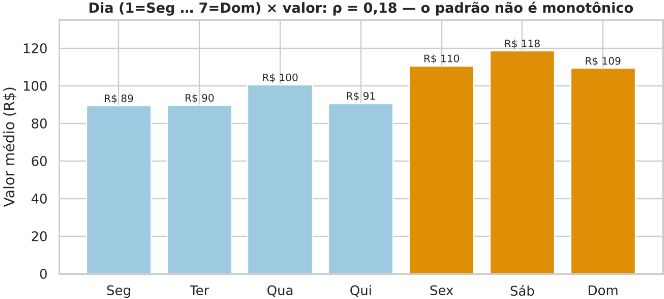

Há um padrão claro (fim de semana mais caro), mas o ρ = 0,18 é fraco, porque a relação com a ordem dos dias não é consistente. Aqui o certo é tratar o dia como categoria e comparar grupos (gráfico de barras, boxplot), e não calcular uma correlação. Antes de qualquer coeficiente: olhe o gráfico .

### Parte III - Aplicações nos datasets da aula

Matrizes, subgrupos, escalas ordinais e dados agregados

### 11. Matriz de Spearman e comparação com Pearson NÍVEL 4

Com o pandas, basta trocar o método: df[colunas].corr(method="spearman") .

Figura 6 - Matrizes de Spearman dos dois datasets (compare com as de Pearson no material irmão).

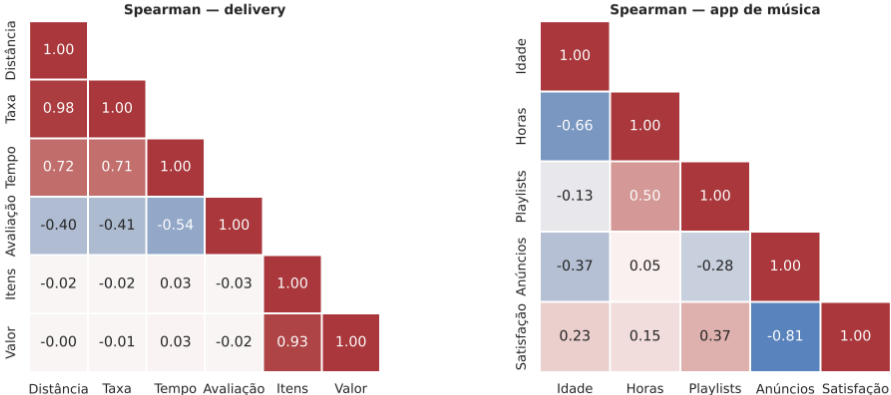

Na maioria dos pares, ρ e r são muito parecidos - sinal de relações aproximadamente lineares e sem outliers decisivos. Vale olhar onde eles mais diferem :

| Dataset | Par | Pearson r | Spearman ρ | ρ - r |
|-----------|----------------------|-------------|--------------|---------|
| Música | Anúncios × Horas | -0,01 | 0,05 | 0,06 |
| Música | Satisfação × Horas | 0,21 | 0,15 | -0,06 |
| Delivery | Avaliação × Tempo | -0,59 | -0,54 | 0,06 |
| Música | Playlists × Horas | 0,54 | 0,50 | -0,04 |
| Música | Anúncios × Playlists | -0,32 | -0,28 | 0,04 |
| Delivery | Valor × Taxa | 0,03 | -0,01 | -0,04 |

Como ler: diferenças pequenas (menos de 0,1) não mudam a conclusão. Quando a diferença é grande, investigue: outliers (r maior que ρ, puxado por poucos pontos), curvas monotônicas (ρ maior que r) ou variáveis com muitos empates/discretas (como a avaliação e as playlists).

In [ ]:
dif = (df[cols].corr("spearman") - df[cols].corr("pearson")).round(2)
dif.where(dif.abs() >= 0.05)      # mostra só as diferenças relevantes

### 12. O que pesa na nota do cliente? Spearman por subgrupo NÍVEL 4

Como a avaliação é ordinal, o ρ é a medida adequada para relacioná-la com o tempo de entrega. Calculado por subgrupo:

Figura 7 - A relação tempo × avaliação em cada subgrupo.

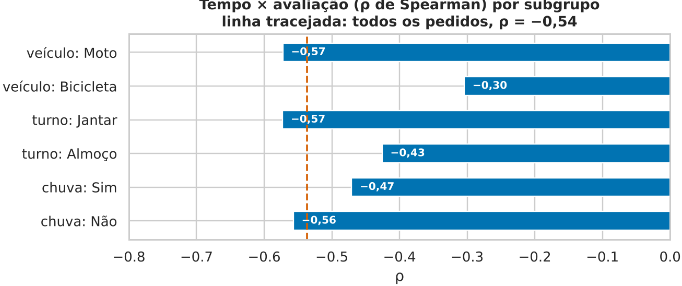

In [ ]:
for col in ["chuva", "turno", "veiculo"]:
    for nome, g in df.groupby(col):
        rho = stats.spearmanr(g["tempo_entrega_min"], g["avaliacao"]).statistic
        print(col, nome, len(g), round(rho, 2))

Leitura: a relação é negativa em todos os grupos. É mais fraca na bicicleta (ρ = -0,30), que só faz entregas curtas - de novo a restrição de amplitude : com pouca variação no tempo, a ordem das notas fica menos previsível. No jantar a relação é mais forte que no almoço.

### 13. App de música: escalas, contagens e grupos NÍVEL 4

| Par | Grupo | Pearson r | Spearman ρ | Comentário |
|-----------------------|-------------|-------------|--------------|----------------------------------------------------------------------------|
| Anúncios × satisfação | todos | -0,82 | -0,81 | inflado pelo plano (Premium: 0 anúncios e satisfação alta) |
| Anúncios × satisfação | só Gratuito | -0,42 | -0,39 | relação real, moderada; satisfação 0-10 é quase ordinal: ρ é o mais seguro |
| Playlists × horas | todos | 0,54 | 0,50 | playlists é uma contagem com só 13 valores distintos (muitos empates) |
| Idade × horas | todos | -0,65 | -0,66 | relação aproximadamente linear: os dois concordam |

O Spearman não resolve variáveis de confusão: o ρ geral de anúncios × satisfação (-0,81) é tão inflado pelo plano quanto o r. Estratificar (calcular por grupo) continua necessário.

### 14. Cuidado com dados agregados NÍVEL 4

Agrupando os pedidos por bairro (5 bairros), calculamos a distância média e a mediana do tempo de cada um. O resultado: ρ = 1 entre distância média e tempo mediano, e ρ = -1 entre distância média e avaliação média.

In [ ]:
b = df.groupby("bairro").agg(dist=("distancia_km", "mean"),
                             tempo=("tempo_entrega_min", "median"),
                             aval=("avaliacao", "mean"))
b.corr(method="spearman")      # ρ = 1 e ρ = −1 com apenas 5 linhas

### CORRELAÇÃO PERFEITA COM 5 PONTOS

(1) Com n = 5, ρ = ±1 acontece com facilidade: basta a ordem dos bairros coincidir. O p-valor que o SciPy devolve nesse caso não é confiável. (2) Agregar esconde a variação dentro dos grupos : no nível dos pedidos, distância × tempo tem ρ = 0,72, não 1. Concluir sobre indivíduos a partir de médias de grupos é a falácia ecológica .

### 15. Pearson ou Spearman? Quadro de decisão

| Situação | Use | Por quê |
|----------------------------------------------------------------------------------|-------------------------------------|------------------------------------------------------------------------|
| Duas variáveis numéricas, relação aproximadamente linear, sem outliers decisivos | Pearson (pode reportar os dois) | usa toda a informação dos valores; liga-se à reta de regressão e ao r² |
| Pelo menos uma variável ordinal (notas, escalas, níveis) | Spearman | só a ordem é confiável |
| Relação monotônica, mas curva | Spearman | mede consistência da ordem, não ajuste a uma reta |
| Outliers que você não pode (ou não deve) remover | Spearman (e investigue os outliers) | postos limitam a influência de valores extremos |
| Muitos empates ou amostra pequena | Spearman ou Kendall | Kendall lida bem com empates |
| Relação em "U" ou "∩", ou variável categórica nominal | nenhum dos dois | use gráficos e comparação de grupos |

Boa prática: calcule os dois. Se concordam, a conclusão é robusta. Se discordam, a diferença é uma pista: volte ao gráfico.

### Parte IV - Exercícios progressivos

Do conceitual à aplicação; respostas no Apêndice B

### Exercício 1 NÍVEL 1

Classifique cada relação como linear, monotônica não linear ou não monotônica: (a) distância × taxa de entrega, em que cada km a mais soma sempre o mesmo valor à taxa; (b) horas de estudo × nota, que sobe rápido e depois se estabiliza perto de 10; (c) idade × horas de sono, maior em bebês e idosos e menor em adultos.

### Exercício 2 NÍVEL 1

Atribua postos (com posto médio nos empates) às avaliações [3, 5, 4, 4, 2, 5, 4].

### Exercício 3 NÍVEL 2

Calcule à mão o ρ de Spearman para x = [2, 4, 6, 8, 10, 12] e y = [3,0; 2,5; 5,0; 4,5; 8,0; 7,0] usando a fórmula com Σd². Confira com stats.spearmanr .

### Exercício 4 NÍVEL 2

Por que a fórmula ρ = 1 - 6Σd² / [n(n² - 1)] não deve ser usada quando há muitos empates? O que fazer nesse caso?

### Exercício 5 NÍVEL 3

Para cada situação, escolha Pearson, Spearman ou nenhum: (a) avaliação (1-5) × tempo de entrega; (b) distância × taxa de entrega; (c) dia da semana (1-7) × valor do pedido; (d) horas ouvidas × satisfação (0-10) com alguns usuários extremos.

### Exercício 6 NÍVEL 3

Um colega encontrou r = 0,87 e ρ = 0,69 em 13 pedidos. O que essa diferença sugere? O que ele deveria fazer?

### Exercício 7 NÍVEL 4

No dataset de delivery, calcule em Python o ρ entre avaliação e valor do pedido. Interprete o resultado e compare com a relação avaliação × tempo.

### Exercício 8 NÍVEL 4

No nível dos bairros, distância média × tempo mediano tem ρ = 1, mas no nível dos pedidos ρ = 0,72. Explique a diferença e qual dos dois números usar para prever o tempo de um pedido específico.

### Apêndice A - Colinha de Spearman em Python

In [ ]:
import pandas as pd
from scipy import stats

df["x"].rank()                                  # postos (empates: posto médio)
df["x"].corr(df["y"], method="spearman")        # ρ (pandas)
res = stats.spearmanr(df["x"], df["y"])          # ρ + p-valor
res.statistic, res.pvalue
stats.pearsonr(df["x"].rank(), df["y"].rank())   # mesmo ρ: Pearson dos postos

df[colunas].corr(method="spearman")             # matriz de Spearman
df[colunas].corr("spearman") - df[colunas].corr("pearson")   # onde diferem

for nome, g in df.groupby("grupo"):              # ρ por subgrupo
    print(nome, stats.spearmanr(g["x"], g["y"]).statistic)

stats.kendalltau(df["x"], df["y"])               # alternativa com muitos empates

### Apêndice B - Respostas dos exercícios

1. (a) linear (e, portanto, também monotônica) - Pearson e Spearman concordam; (b) monotônica não linear - use Spearman; (c) não monotônica (∪) - nenhum coeficiente resume bem; mostre o gráfico ou compare faixas etárias.
2. Ordenando: 2, 3, 4, 4, 4, 5, 5. Postos: 2 → 1; 3 → 2; os três "4" ocupam 3, 4, 5 → 4; os dois "5" ocupam 6 e 7 → 6,5. Na ordem original: [2; 6,5; 4; 4; 1; 6,5; 4].
3. Postos de x: 1 a 6. Postos de y: 3,0 → 2; 2,5 → 1; 5,0 → 4; 4,5 → 3; 8,0 → 6; 7,0 → 5. d = -1, +1, -1, +1, -1, +1 → Σd² = 6. ρ = 1 - 6 × 6 / (6 × 35) = 1 - 36/210 = 0,829 . stats.spearmanr(x, y).statistic → 0,829.
4. A fórmula com Σd² é um atalho derivado supondo postos 1, 2, …, n sem repetição. Com empates, os postos médios mudam as variâncias dos postos e a fórmula fica imprecisa (na Seção 5 deu -0,73 em vez de -0,84). Calcule o Pearson dos postos - é o que spearmanr e corr(method="spearman") fazem.
5. (a) Spearman (avaliação é ordinal); (b) Pearson (numéricas, relação linear - e quase redundantes); (c) nenhum: o padrão não é monotônico; compare os dias como categorias; (d) Spearman (e investigue os extremos), ou os dois para comparar.
6. r bem maior que ρ sugere que poucos pontos extremos estão "puxando" o Pearson (Seção 7 do material de Pearson: um pedido a 14 km). Ele deve olhar o gráfico, identificar e investigar o ponto, reportar r com e sem ele e considerar o ρ como medida principal.

7. df["avaliacao"].corr(df["valor\_pedido"], method="spearman") = -0,021: praticamente nenhuma relação - o valor do pedido não influencia a nota. Já avaliação × tempo tem ρ = -0,54: a nota depende da demora, não do tamanho do pedido.
8. As médias/medianas por bairro eliminam a variação entre pedidos do mesmo bairro, e com apenas 5 pontos uma ordem perfeita é fácil de ocorrer. Para prever o tempo de um pedido específico vale a relação individual (ρ = 0,72, ou o Pearson e a reta de regressão), que mostra quanta incerteza existe pedido a pedido. O ρ = 1 descreve só a ordem dos bairros.

### Referências

- SPEARMAN, C. The proof and measurement of association between two things. The American Journal of Psychology , v. 15, n. 1, p. 72-101, 1904. ·
- BUSSAB, W. O.; MORETTIN, P . A. Estatística Básica . 9. ed. São Paulo: Saraiva, 2017. ·
- FIELD, A. Descobrindo a estatística usando o SPSS . 2. ed. Porto Alegre: Artmed, 2009 - cap. Correlação (Spearman e Kendall). ·
- SIEGEL, S.; CASTELLAN JR., N. J. Estatística não-paramétrica para ciências do comportamento . 2. ed. Porto Alegre: Artmed, 2006. ·
- SciPy - documentação de scipy.stats.spearmanr e kendalltau ; pandas - Series.rank e DataFrame.corr . ·